In [1]:
import cPickle as pickle
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture
from sklearn.cluster import KMeans, SpectralClustering

from neo.core import SpikeTrain, Unit, Segment, Block, ChannelIndex

from spikes.plotting import plot_waveform_overlay

from config import config

%load_ext autoreload
%autoreload 2

In [2]:
BIRD = "LbY6074__161215_145633"
ELEC = 5

In [3]:
DATADIR = config.get("project", "datadir")
data_path = os.path.join(DATADIR, "birds", "LbY6074", "RHD", "{}-thresholded.pkl".format(BIRD))
# ../../data/birds/LbY6074/RHD/LbY6074__161215_145633.

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [6]:
from spikes.sorting.preprocess import binned_spikes, collect_waveforms, make_V

In [143]:
collect_waveforms(unit.spiketrains, threshold=-70)

(array([[-10.03424949,   1.95615817,   8.97908668, ...,  15.01995071,
          20.1496666 ,  -0.85057917],
        [ 14.66788796,  17.16115105,   3.70911262, ...,  17.14791761,
          23.86499672,  24.3253444 ],
        [ 27.6198252 ,   3.83325668,   2.47293652, ...,  37.64311106,
          44.75659526,  39.68912704],
        ..., 
        [-14.78575749,   1.87623009,   6.27304249, ...,  29.73794612,
          37.32247107,  42.06010739],
        [ 19.16654459,  18.50550587,   2.39294147, ...,   6.40675655,
          -1.2904807 ,  -0.99821968],
        [ 14.82632333,   8.58449082,  -2.40667964, ...,  -2.35391969,
         -15.53019271, -10.51723834]]),
 array([  825.5996 ,   825.6132 ,   825.617  , ...,  5336.70684,
         5336.71924,  5336.73992]))

In [7]:
unit = (
    channel_index.units[0]
    for channel_index in block.channel_indexes
    if channel_index.name == "Amp Elec {}".format(ELEC)
).next()

# Assumes we want to slice the middle 32 time-points of the waveforms
waveforms = collect_waveforms(unit.spiketrains, threshold=-70)[0][:, 8:40]


In [8]:
waveforms = waveforms[np.max(np.abs(waveforms), axis=1) < 300]


In [9]:
pca = PCA(n_components=10)
x = pca.fit_transform(waveforms)

In [10]:
def comparator(x, y, tsne=False):
    if tsne:
        pca = TSNE(n_components=2)
    else:
        pca = PCA(n_components=2)
    x_pca = pca.fit_transform(x)
    
    labels = np.unique(y)
    
    plt.figure(figsize=(5, 5))
    for label in labels:# sorted(labels, key=lambda l: np.sum(y == l)):
        plt.scatter(x_pca[y == label].T[0], x_pca[y == label].T[1], s=1, label=label)
    plt.legend()    
        
    plt.figure()
    for label in labels:# sorted(labels, key=lambda l: np.sum(y == l)):
        plt.plot(np.mean(x[y == label], axis=0), label=label)
    plt.legend()

In [31]:
from spikes.sorting.clustering import KMeansClusterer

In [42]:
k_means_model = KMeansClusterer(pcs=20, n_clusters=16)
k_means_model.fit(waveforms)

In [44]:
y, _ = k_means_model.predict(waveforms)

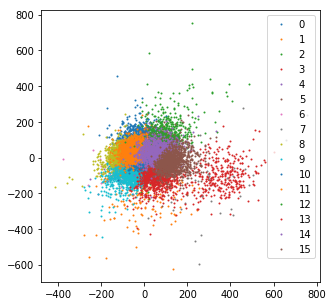

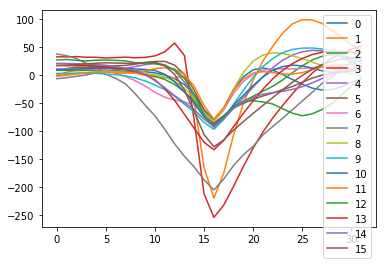

In [140]:
comparator(waveforms, y)
plt.show()

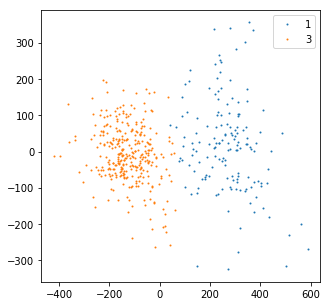

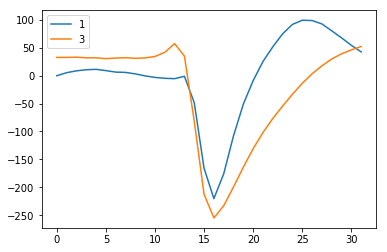

In [51]:
comparator(waveforms[(y==1) | (y==3)], y[(y==1) | (y==3)])
plt.show()

In [53]:
k_means_model.add_good_label(1)
k_means_model.add_good_label(3)

In [134]:
t_arrs, X = binned_spikes(unit, -70, k_means_model)

In [135]:
V = make_V(block, ELEC)

In [70]:
from spikes.sorting import unravel_into_spiketimes, unravel, pursue_iter

In [130]:
for X, V, W in pursue_iter(1, X, V):
    pass


In [94]:
from spikes.plotting import plot_spikes_with_timeseries
from spikes.plotting import raster

In [136]:
t_arrs, spike_times, X_list, V_list = unravel(t_arrs, X, V)

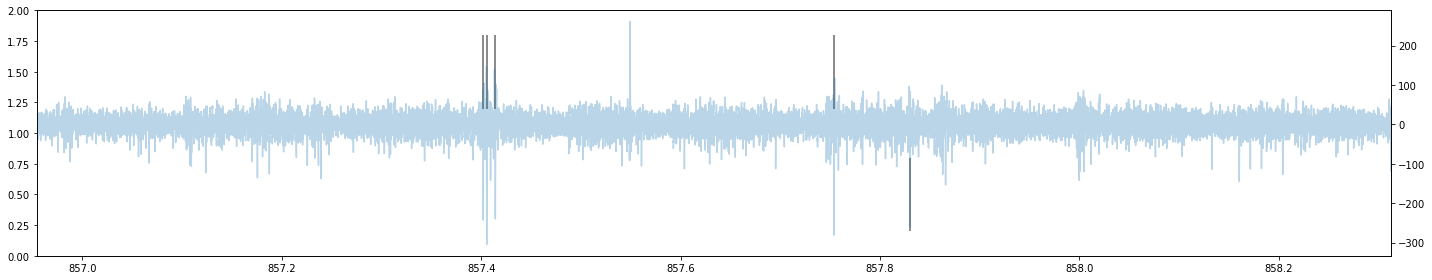

In [139]:
fig, ax = plt.subplots(1, 1, figsize=(20, 4))
ax2 = plt.twinx(ax)
ax2.plot(t_arrs[1], V_list[1], alpha=0.3)

raster.plot(unravel_into_spiketimes(t_arrs[1], X[len(t_arrs[0]):len(t_arrs[0]) + len(t_arrs[1])]),
           t_arrs[1][0],
           t_arrs[1][-1],
           alpha=0.6,
           ax=ax)
plt.tight_layout()
plt.show()


In [145]:
from spikes.sorting.preprocess import binned_spikes, collect_waveforms, make_V, sort_spikes_on_unit

In [259]:
dat = np.load("../../data/birds/LbY6074/RHD/LbY6074__161215_145633-e5-uhsorted.npy")[()]

In [260]:
dat

{'model': KMeans(algorithm='auto', copy_x=True, init='k-means++', max_iter=300,
     n_clusters=20, n_init=10, n_jobs=1, precompute_distances='auto',
     random_state=None, tol=0.0001, verbose=0),
 'units': [[12], [19], [18, 9, 0, 11, 13, 17]]}

In [261]:
res = sort_spikes_on_unit(unit, -70, dat["model"], dat["units"])

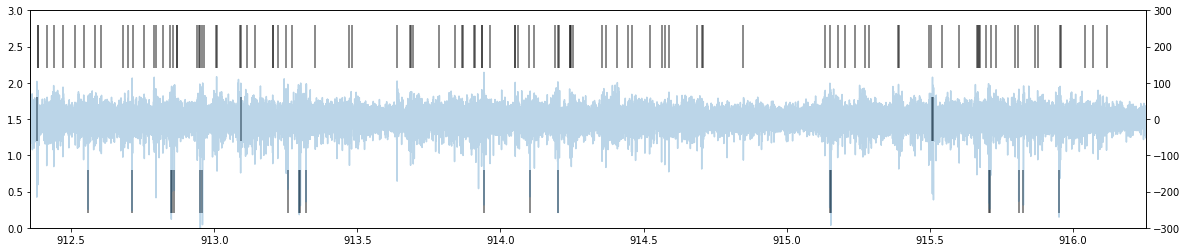

In [262]:
seg = 9
fig, ax = plt.subplots(1, 1, figsize=(20, 4))
ax2 = plt.twinx(ax)
ax2.plot(t_arrs[seg], V_list[seg], alpha=0.3)
raster.plot(res[seg],
           t_arrs[seg][0],
           t_arrs[seg][-1],
           alpha=0.6,
           ax=ax)
ax2.set_ylim(-300, 300)
plt.show()

In [195]:
from neo.core import AnalogSignal


ValueError: You must provide either the sampling rate or sampling period

In [201]:
AnalogSignal(block.segments[0].analogsignals[0],
             sampling_period=block.segments[0].analogsignals[0].sampling_period,
             t_start=block.segments[0].analogsignals[0].t_start,
            annotations=block.segments[0].analogsignals[0].annotations)

AnalogSignal with 2 channels of length 42861; units V; datatype float32 
annotations: {'annotations': {u't_start.units': u's'}}
sampling rate: 25000.0 Hz
time: 825.59228 s to 827.30672 s

In [204]:
from spikes.write_neo import write_neo_new

In [263]:
a = [[] for _ in range(16)]

In [264]:
a[5] = res

In [265]:
new_block = write_neo_new(block, a)

Creating 3 units for electrode 5


In [266]:
new_block.segments[0].spiketrains[0]

SpikeTrain

In [267]:
huh = new_block.channel_indexes[0]

In [268]:
huh

ChannelIndex with 3 units name: 'Amp Elec 5'

In [269]:
huh

ChannelIndex with 3 units name: 'Amp Elec 5'

In [270]:
len(huh.analogsignals)

0

In [279]:
np.array(block.segments[0].analogsignals[0]).shape

(42861, 2)

In [274]:
new_block.segments[0].spiketrains[0]

SpikeTrain

student_song_0
0


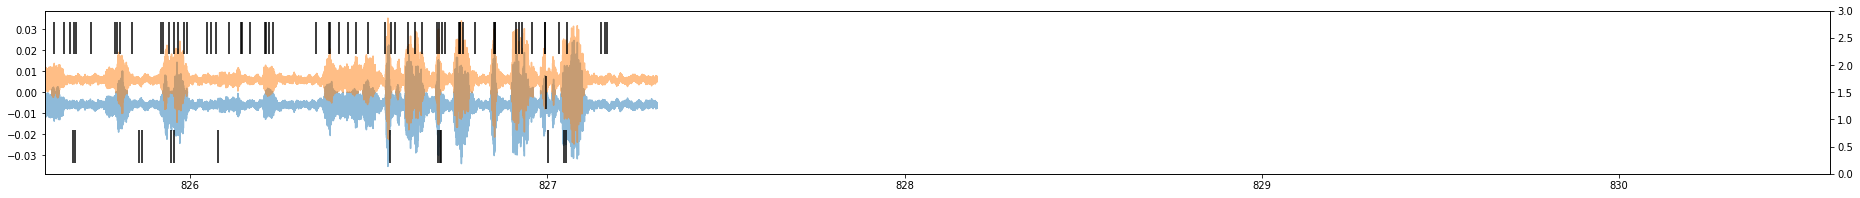

student_song_1
1


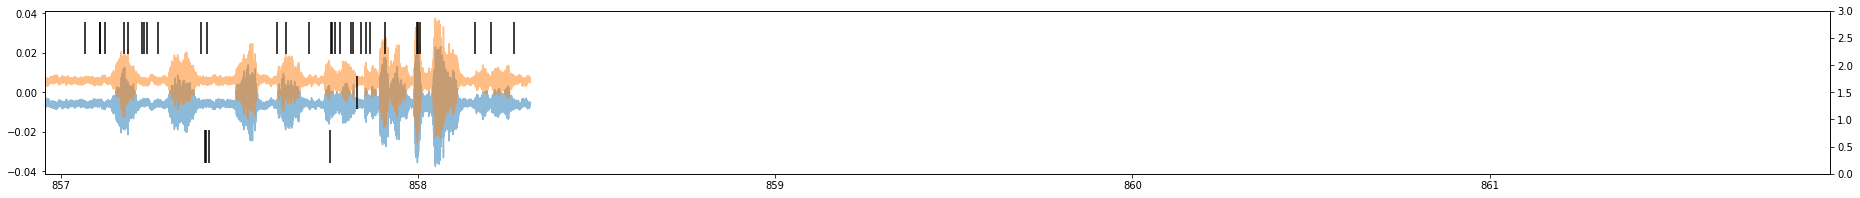

student_song_2
2


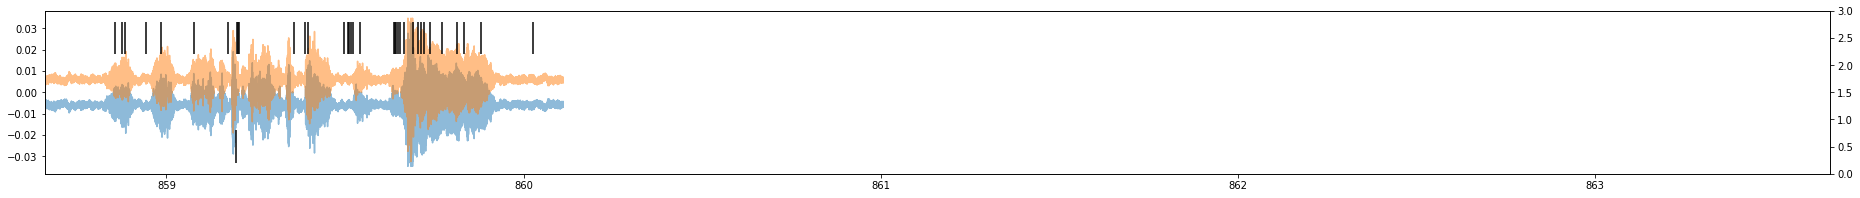

student_song_3
3


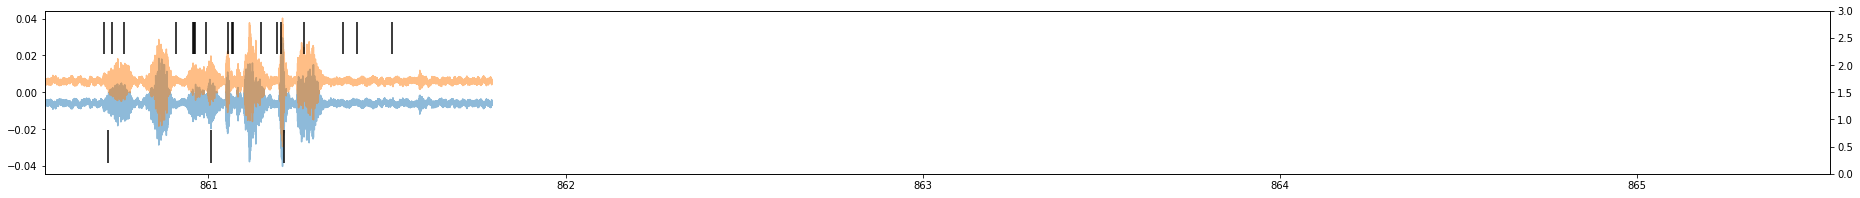

student_song_4
4


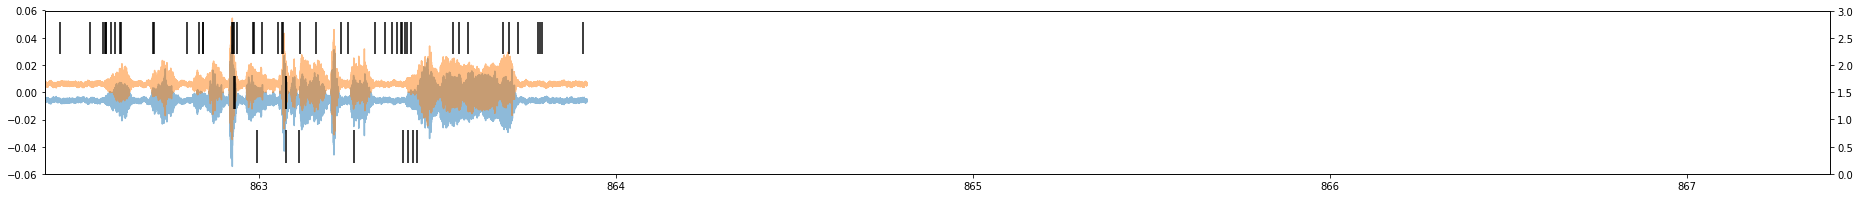

student_song_5
5


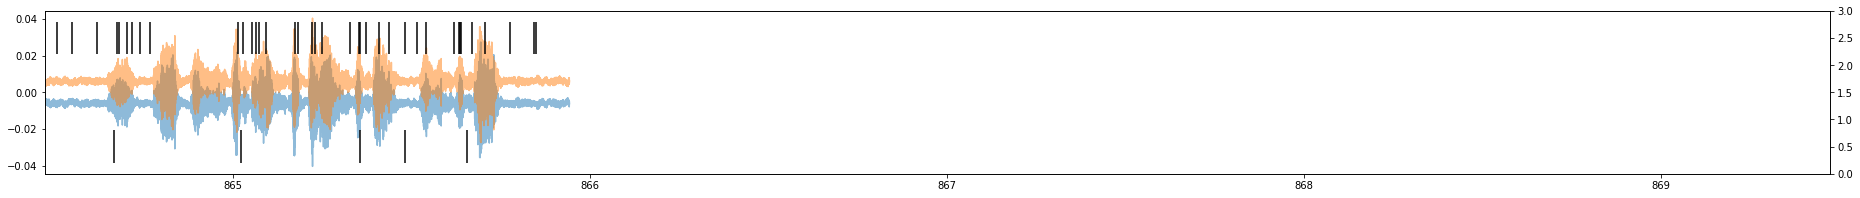

student_song_6
6


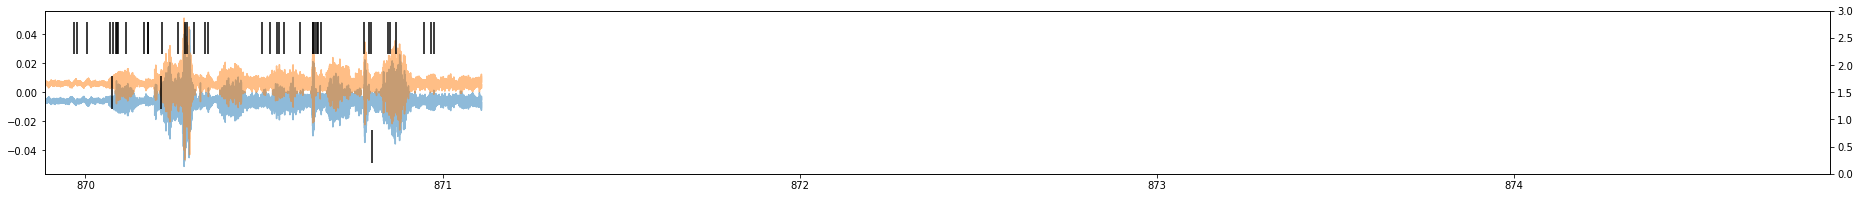

student_song_7
7


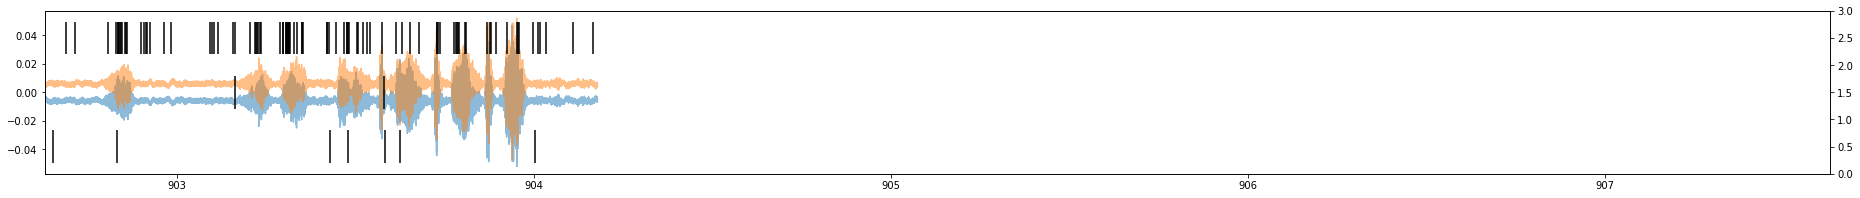

student_song_8
8


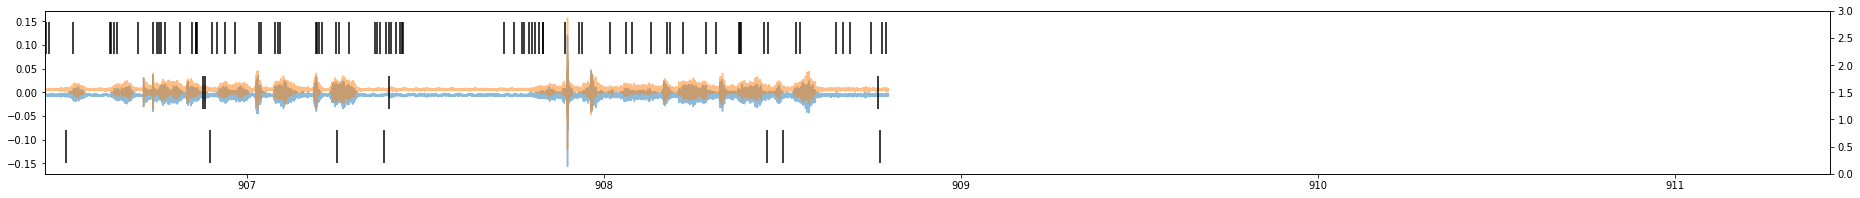

student_song_9
9


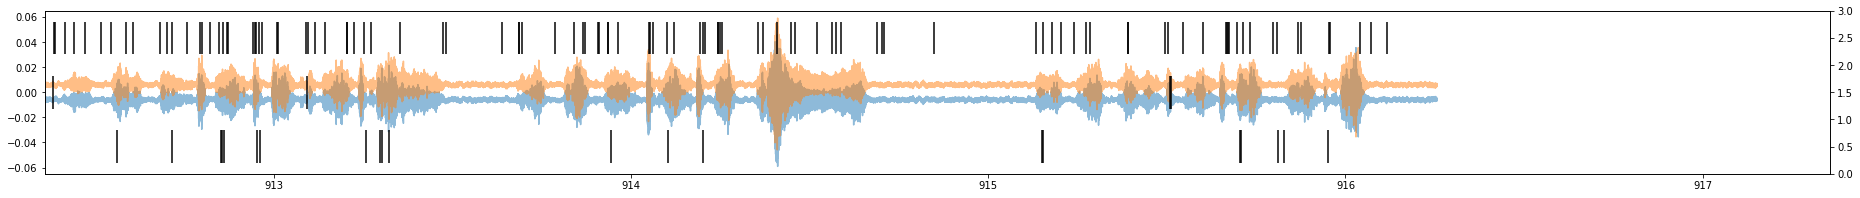

student_song_10
10


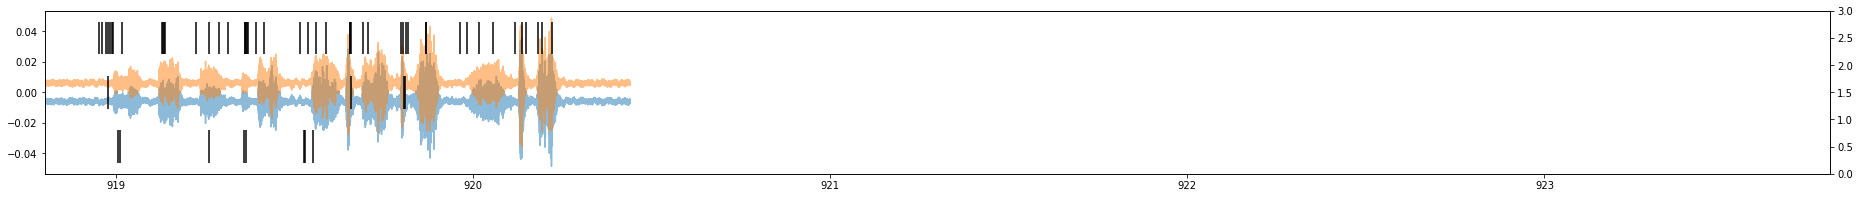

student_song_11
11


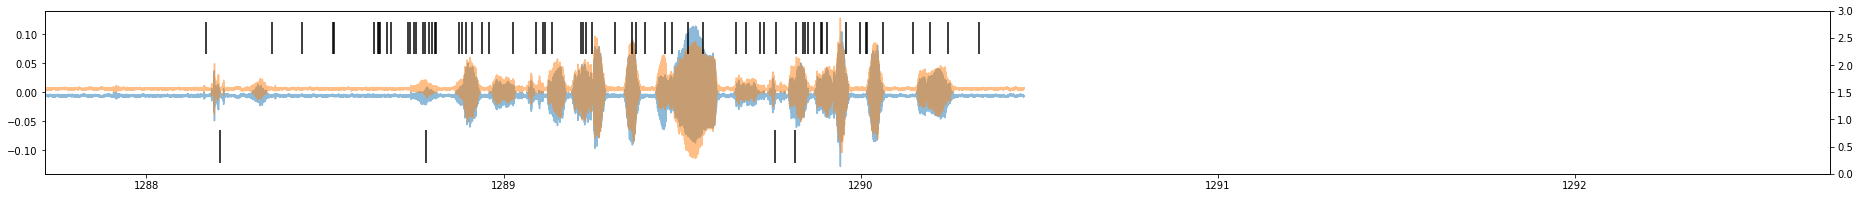

student_song_12
12


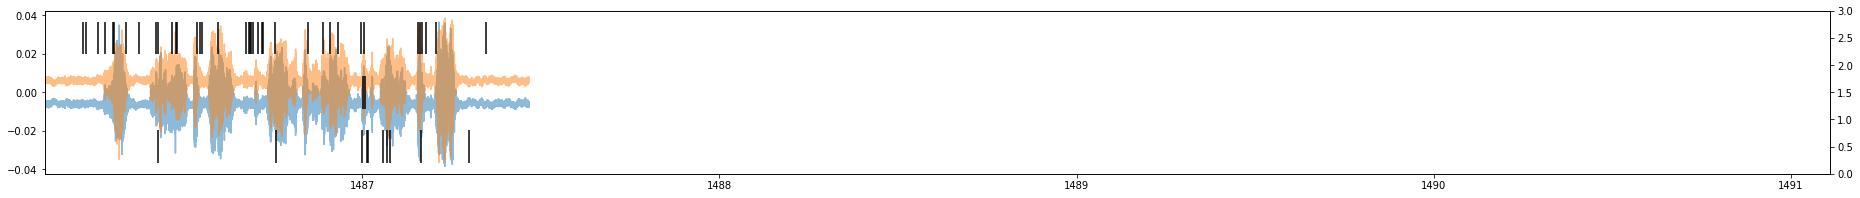

student_song_13
13


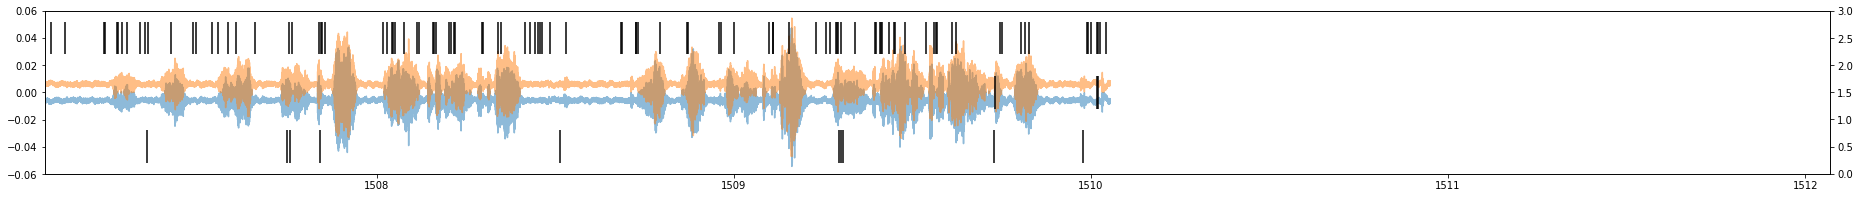

student_song_14
14


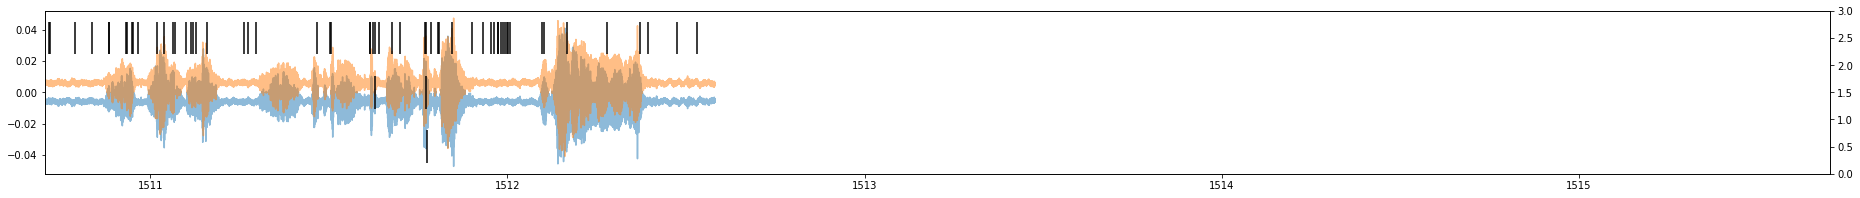

student_song_15
15


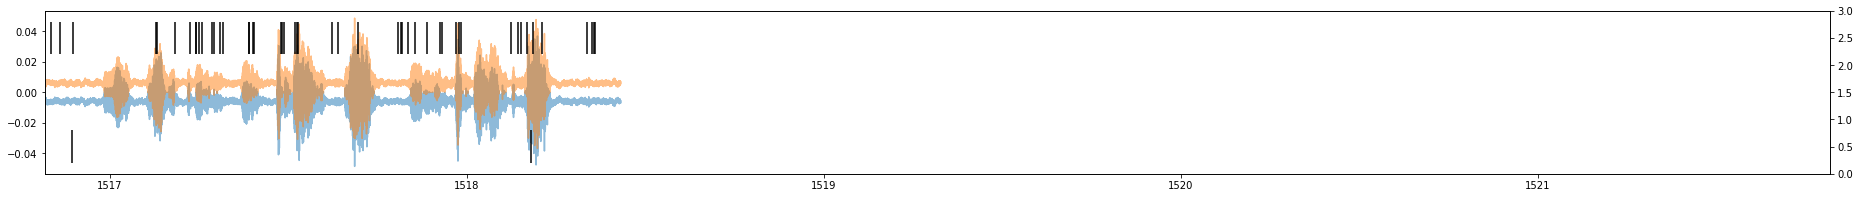

student_song_16
16


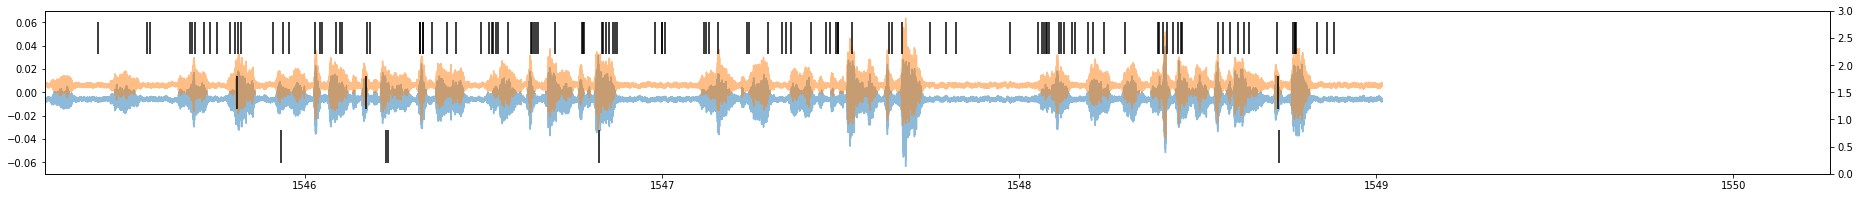

student_song_17
17


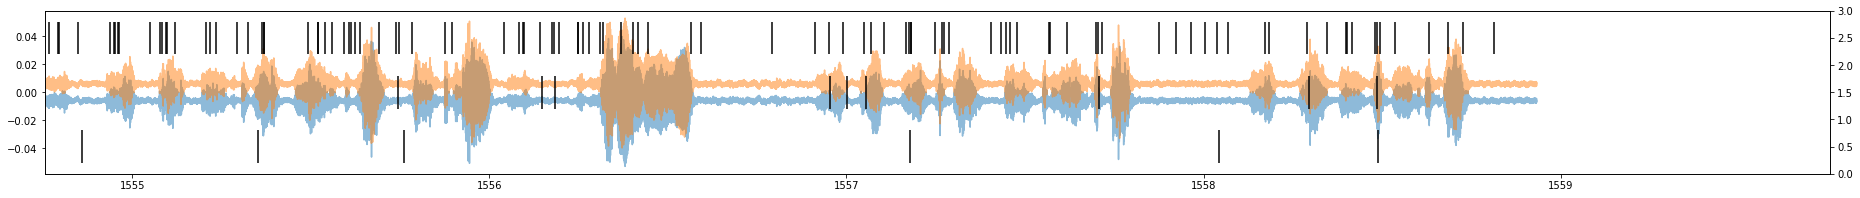

student_song_18
18


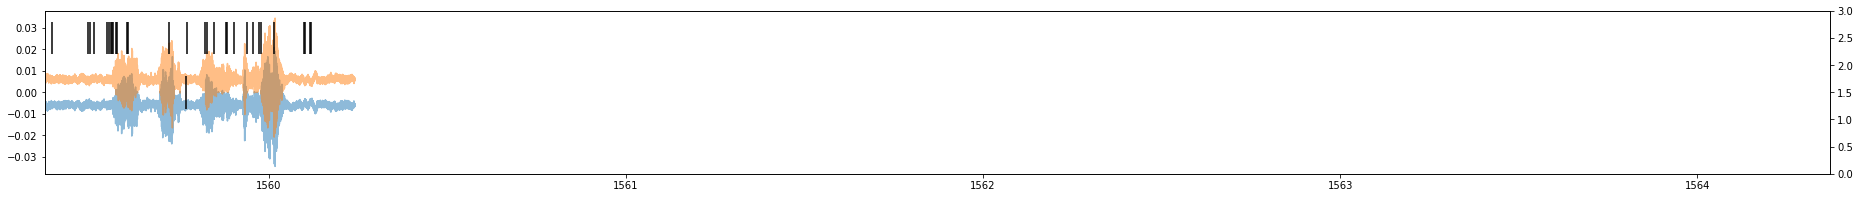

student_song_19
19


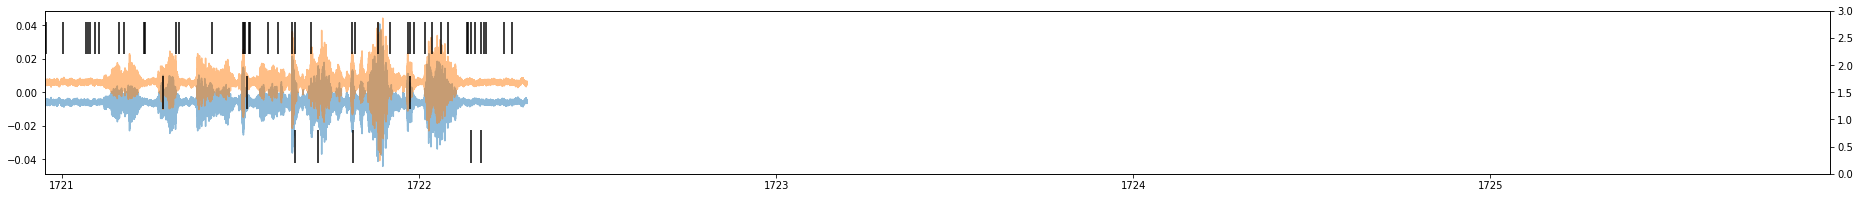

student_song_20
20


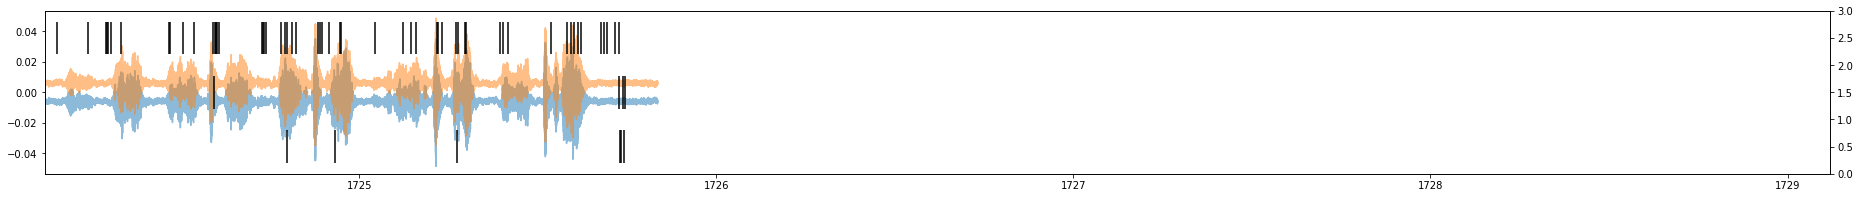

student_song_21
21


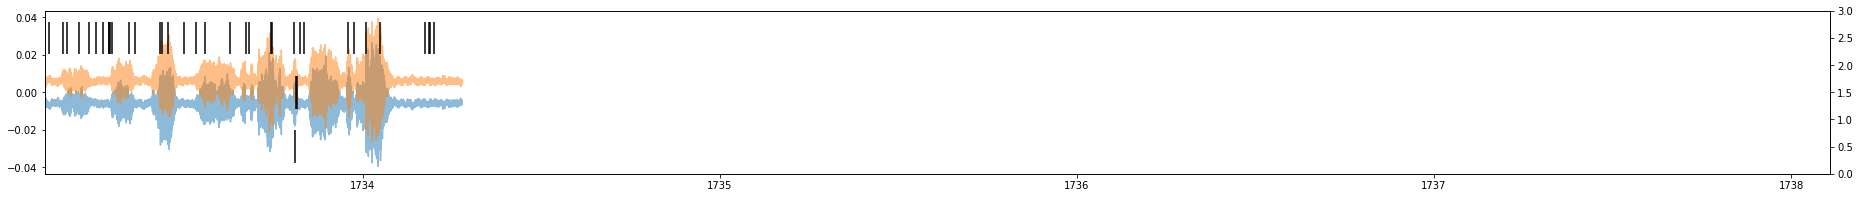

student_song_22
22


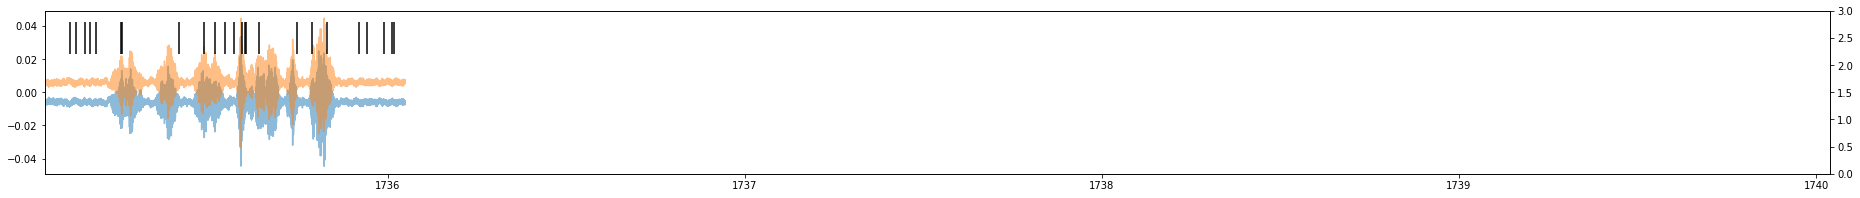

student_song_23
23


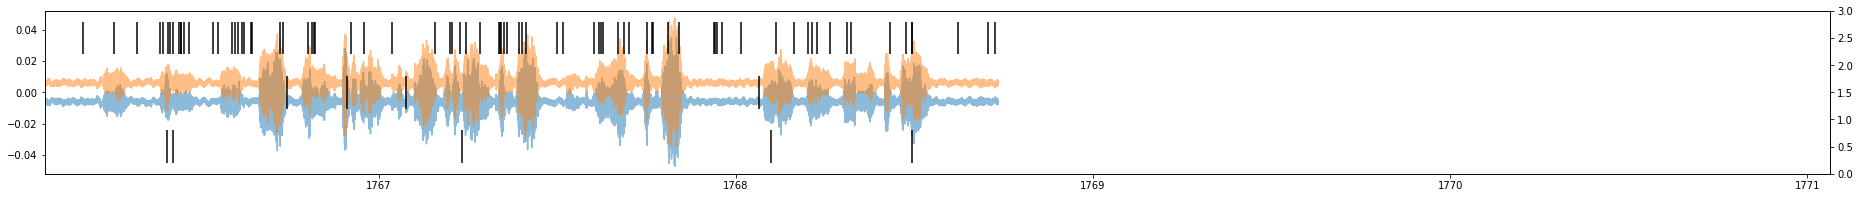

student_song_24
24


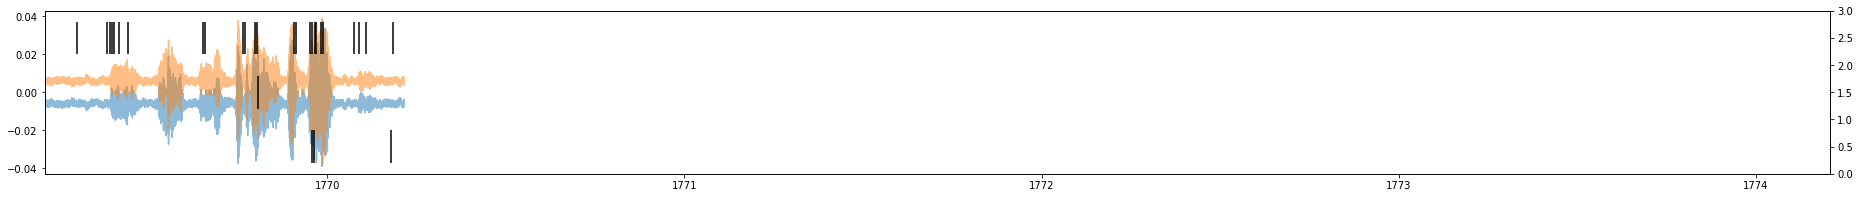

student_song_25
25


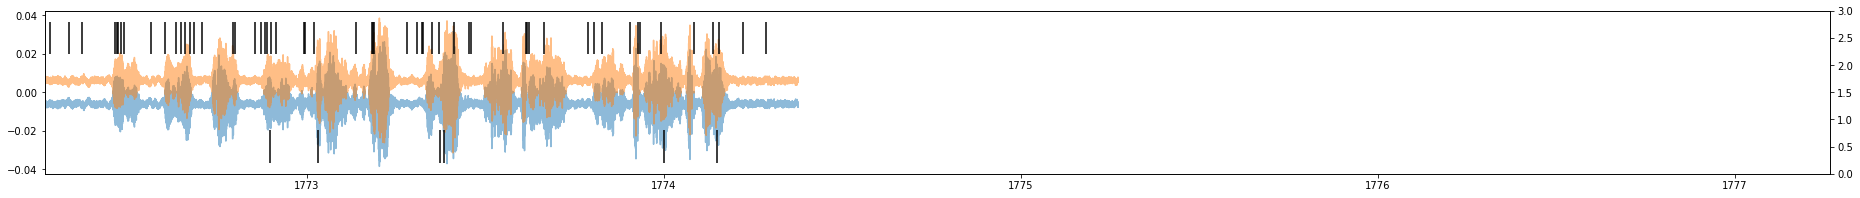

student_song_26
26


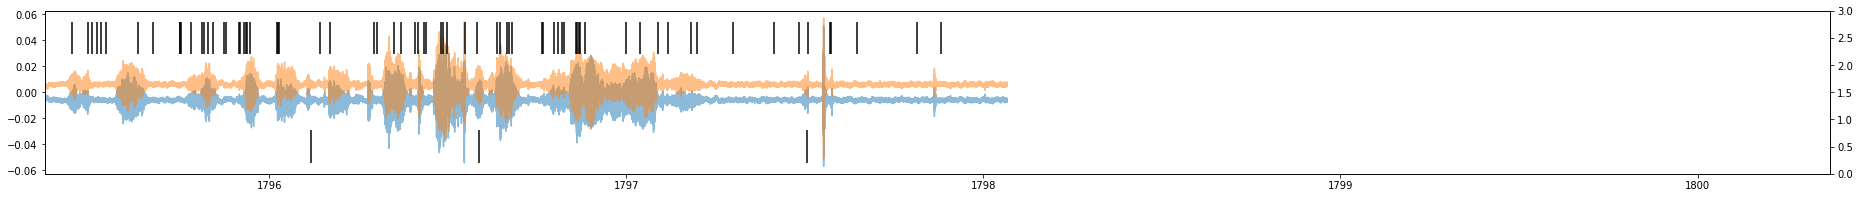

student_song_27
27


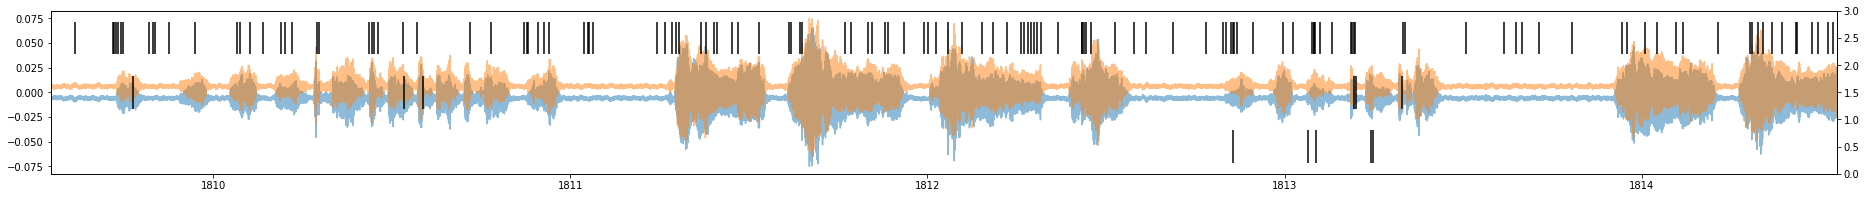

student_song_28
28


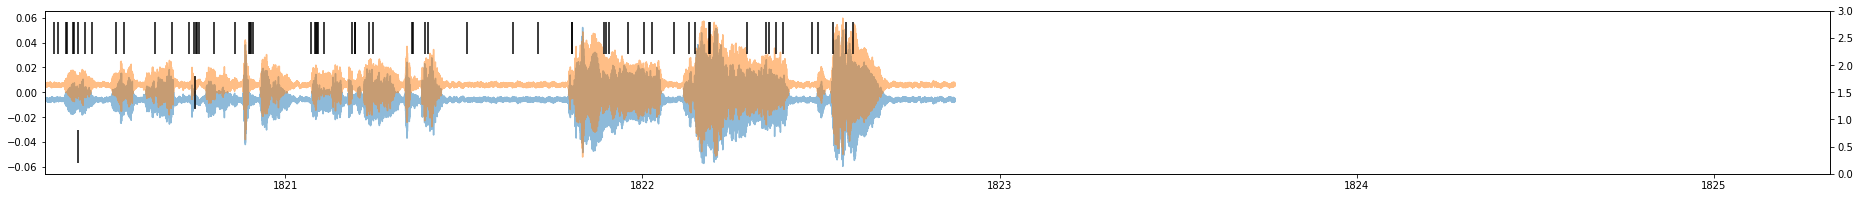

student_song_29
29


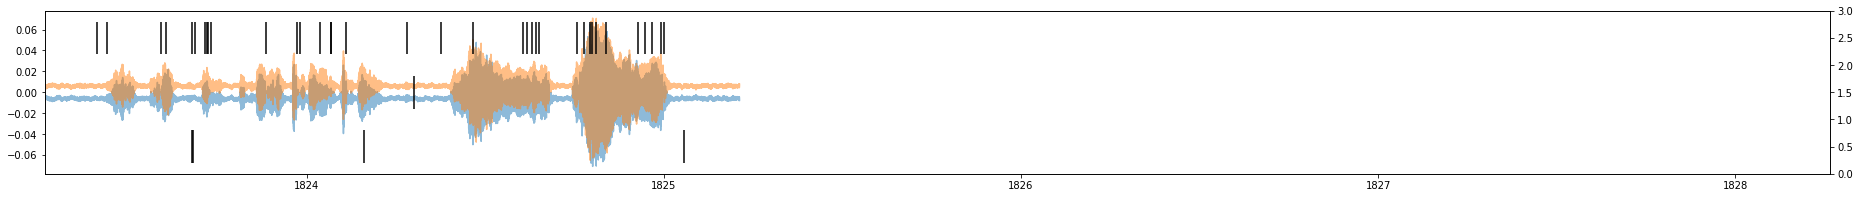

student_song_30
30


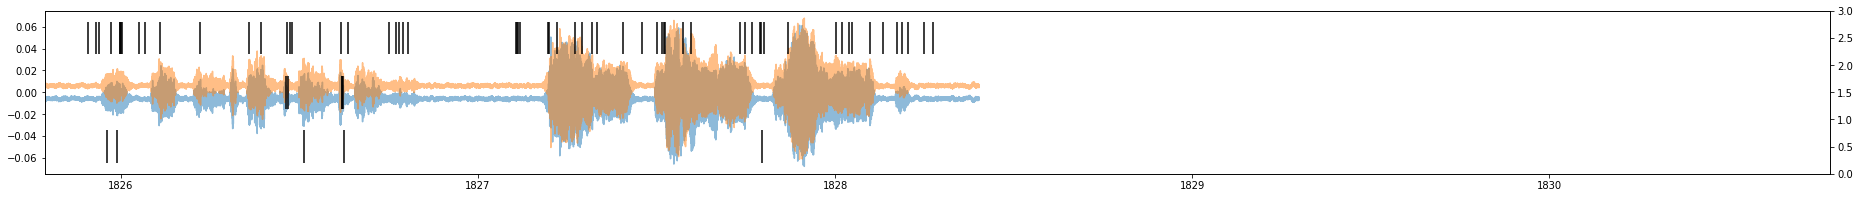

student_song_31
31


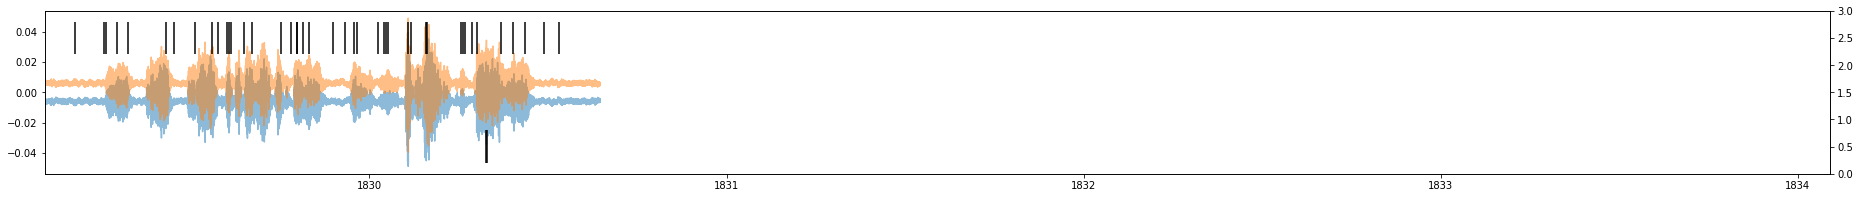

student_song_32
32


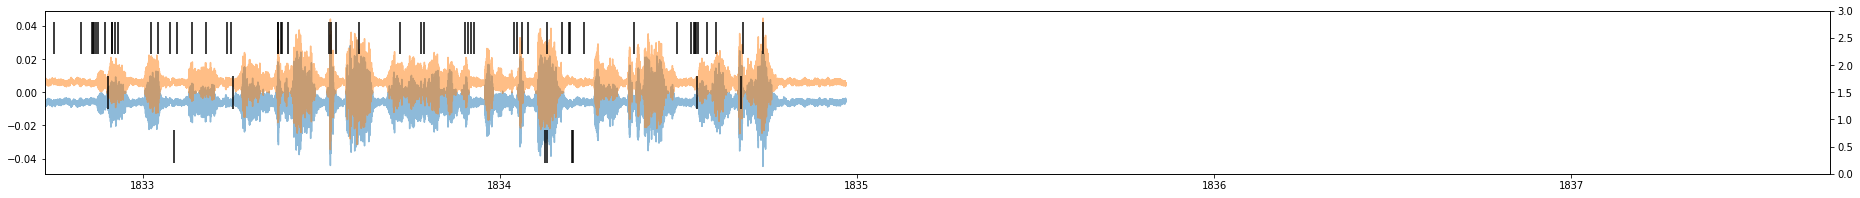

student_song_33
33


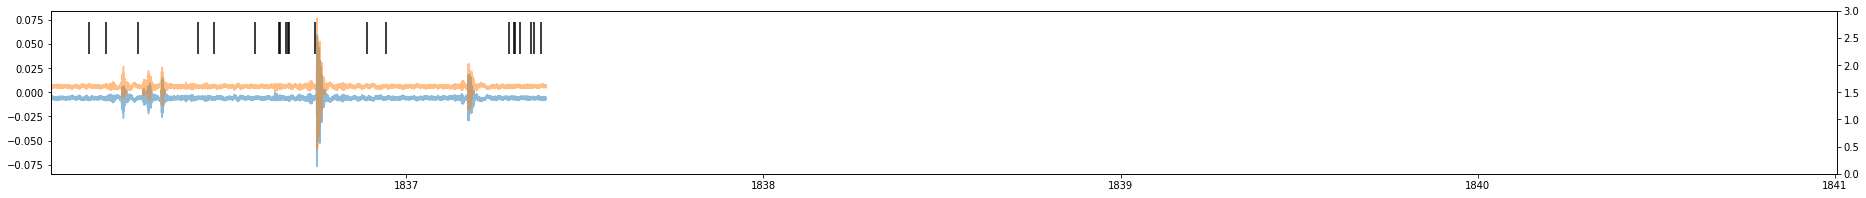

student_song_34
34


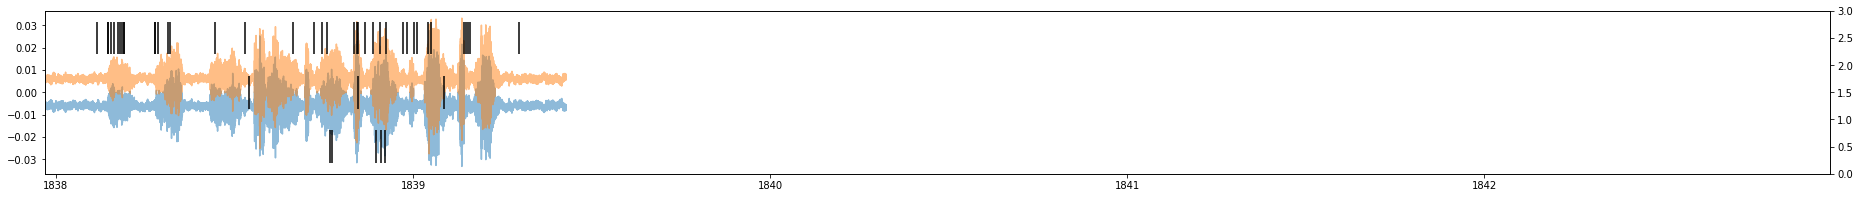

student_song_35
35


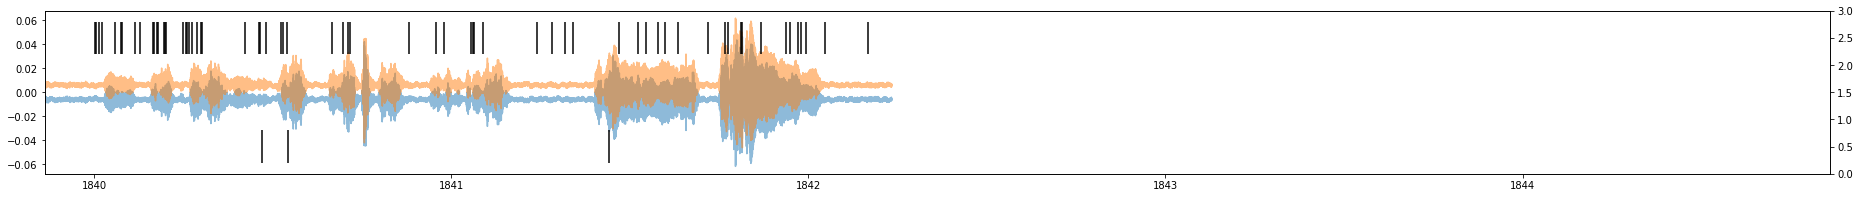

student_song_36
36


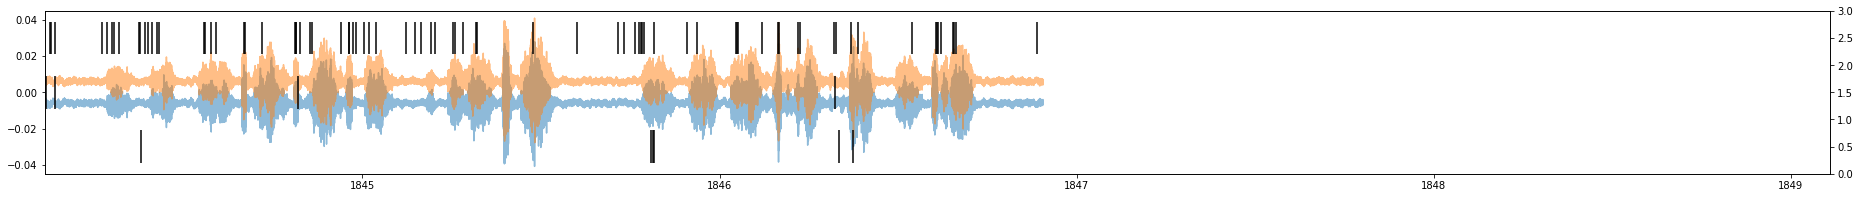

student_song_37
37


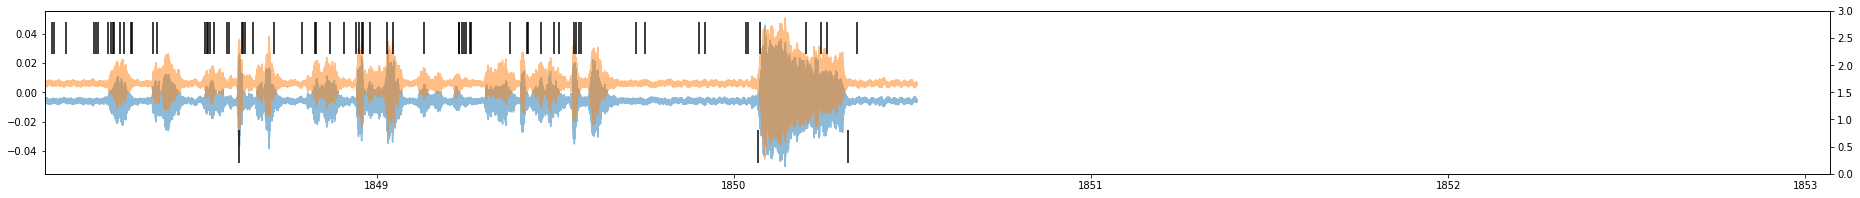

student_song_38
38


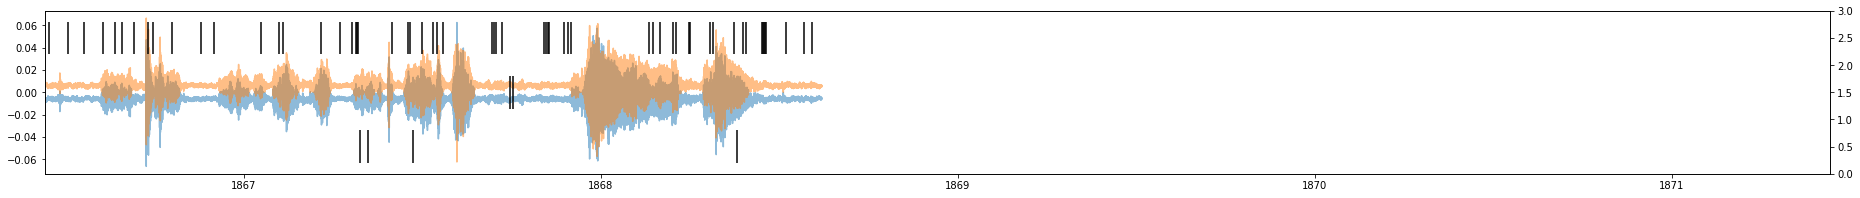

student_song_39
39


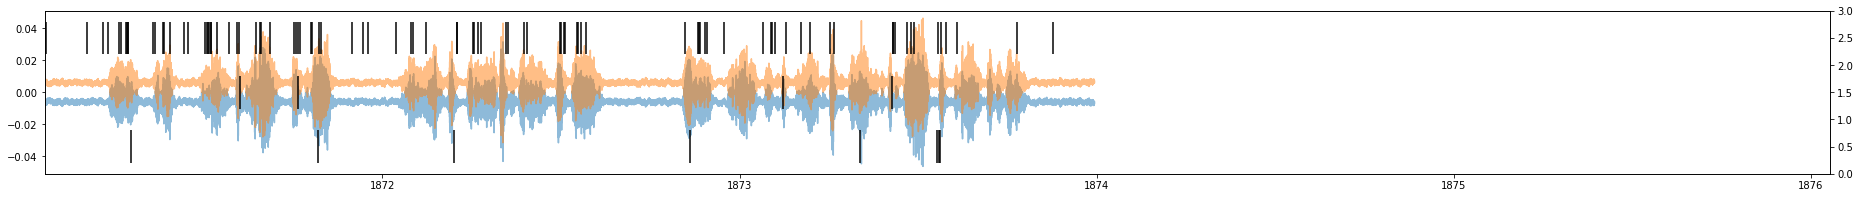

student_song_40
40


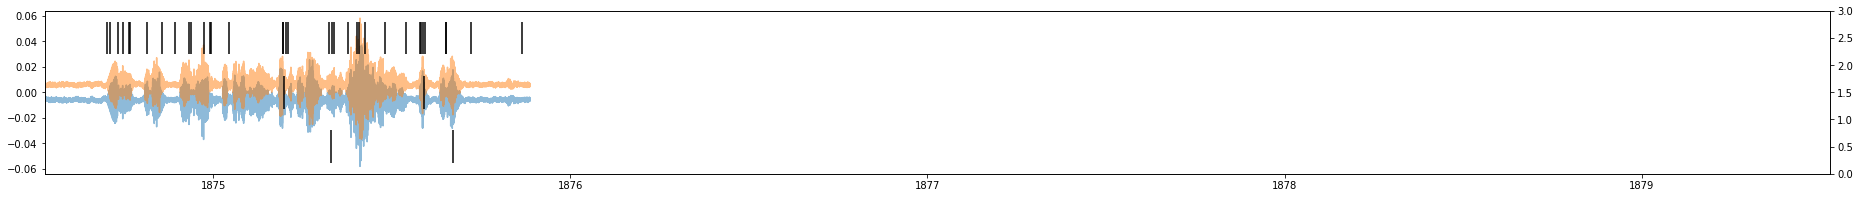

student_song_41
41


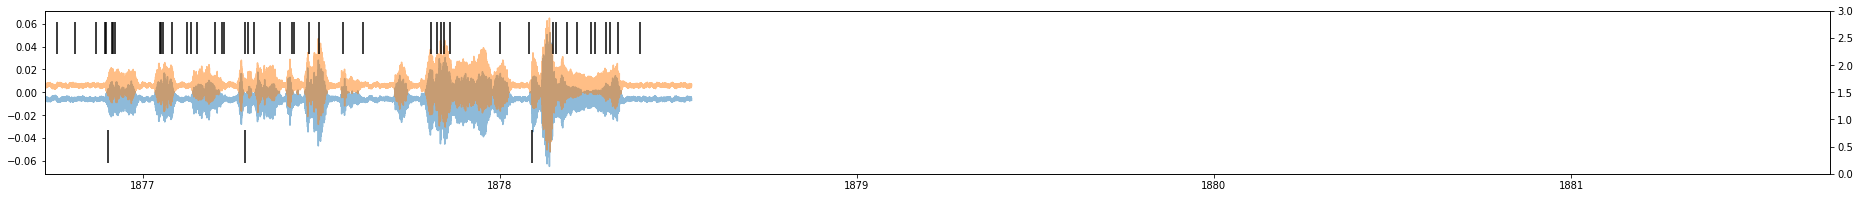

student_song_42
42


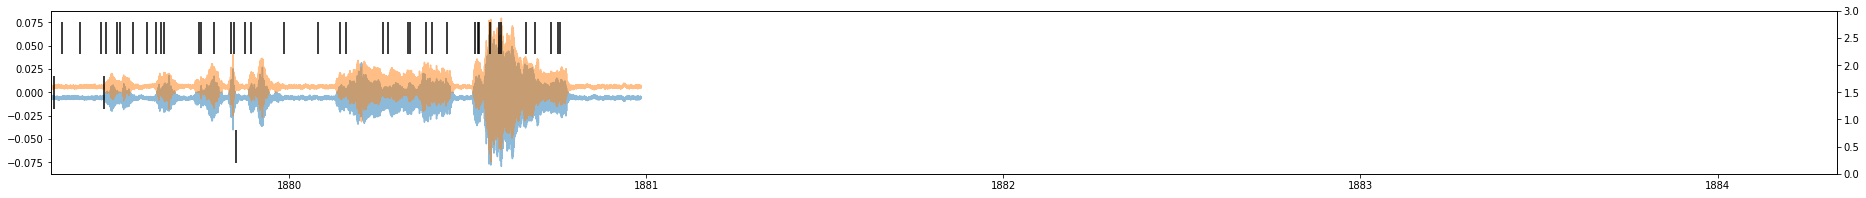

student_song_43
43


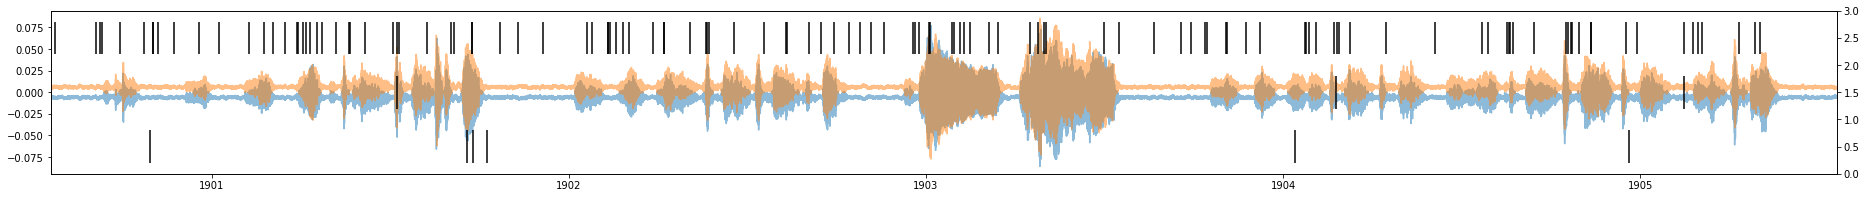

student_song_44
44


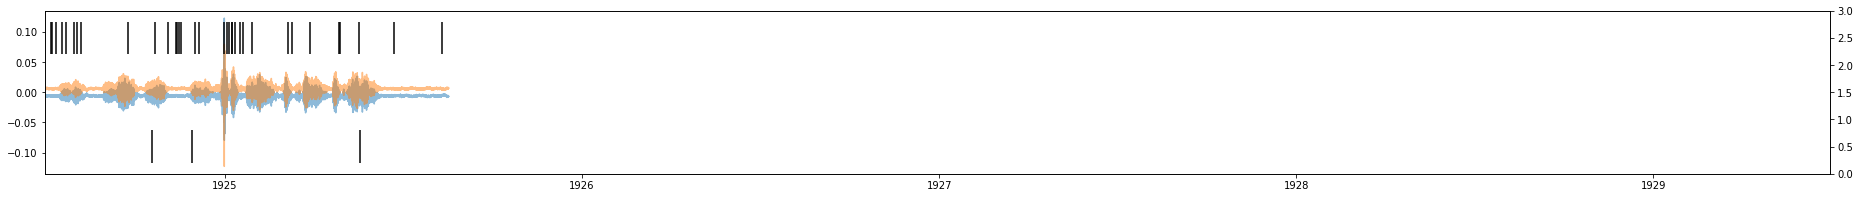

student_song_45
45


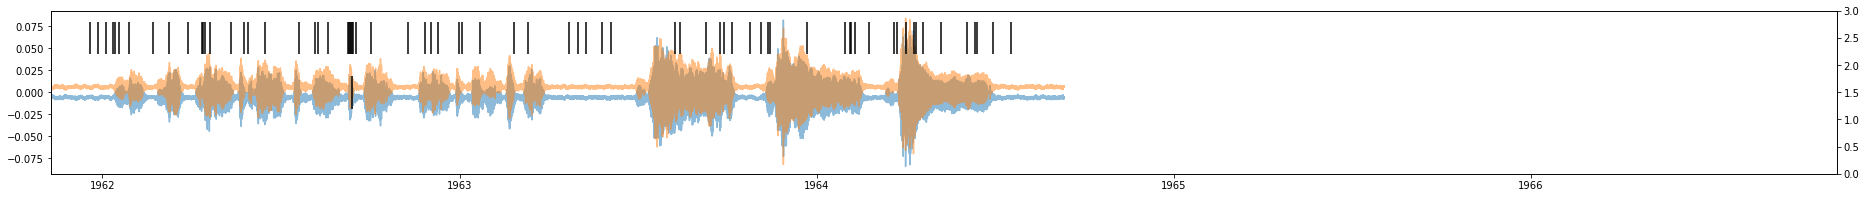

student_song_46
46


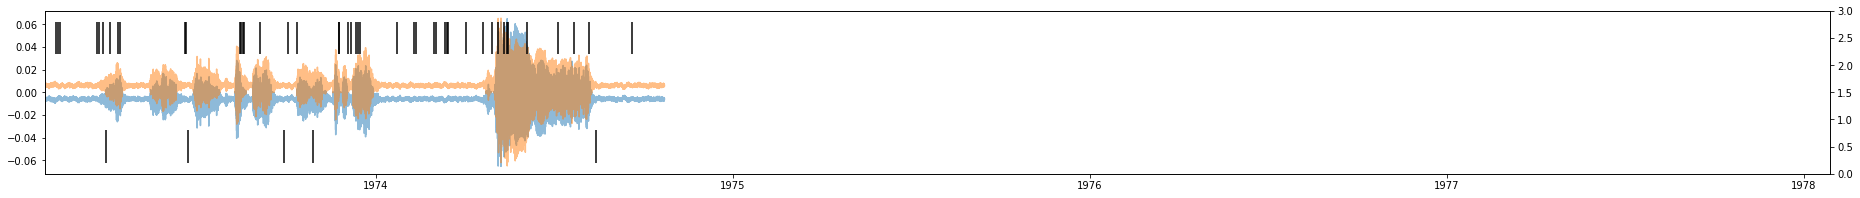

student_song_47
47


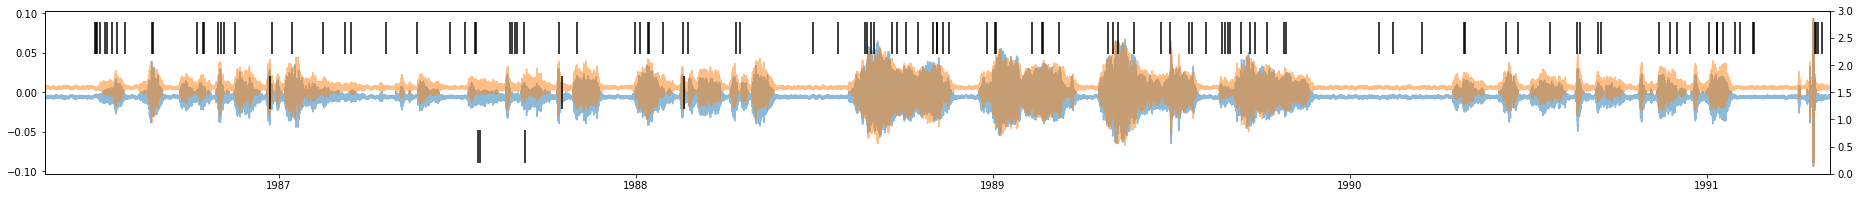

student_song_48
48


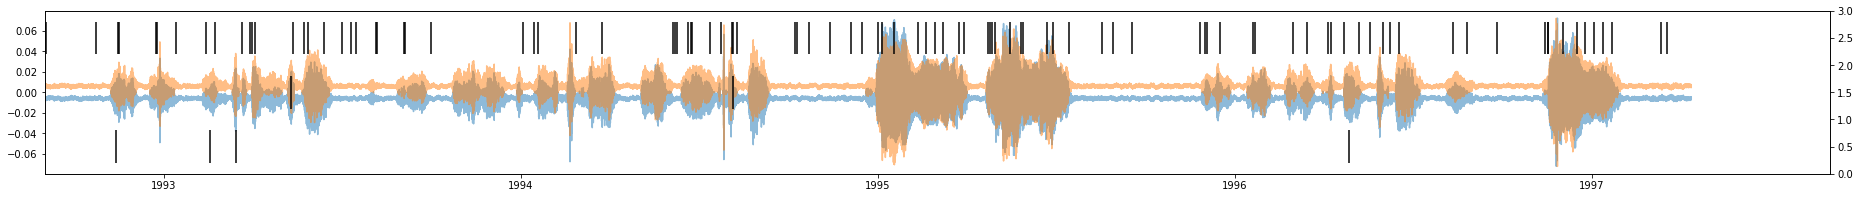

student_song_49
49


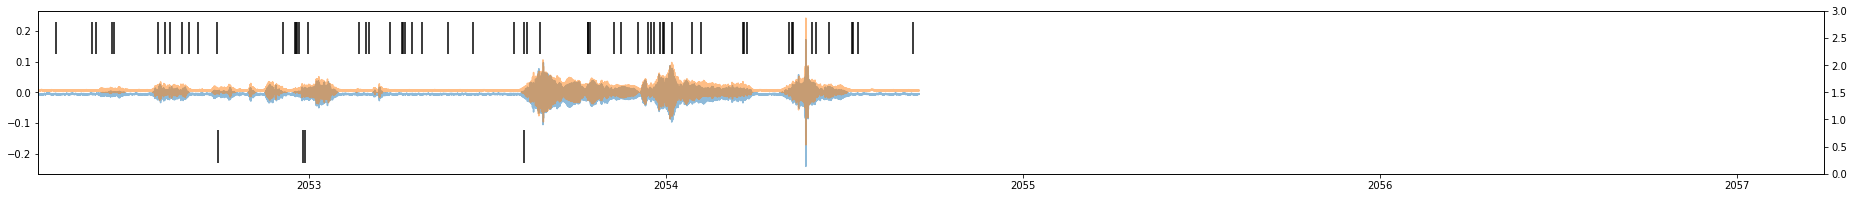

student_song_50
50


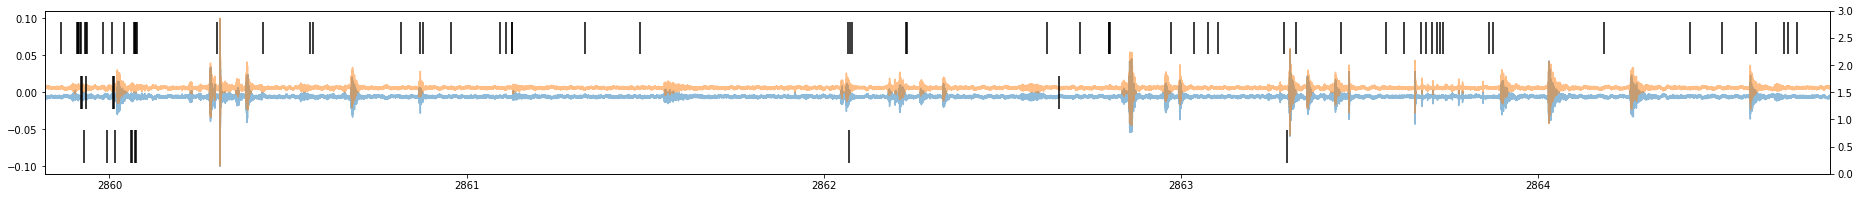

student_song_51
51


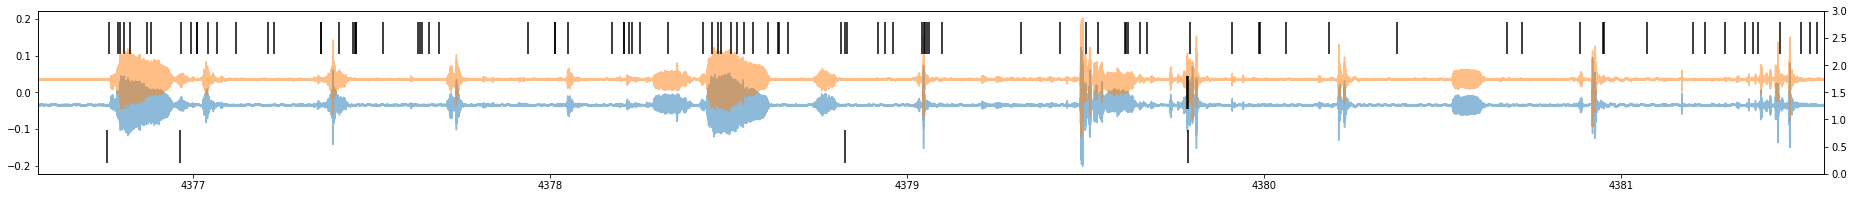

student_song_52
52


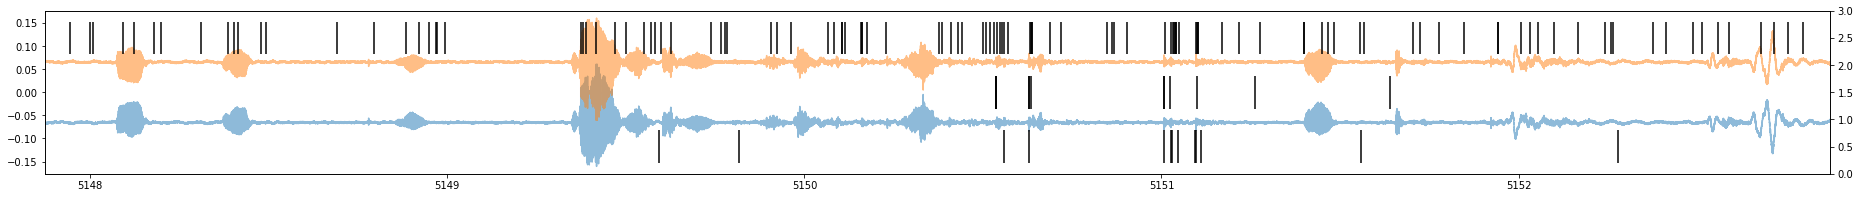

tutor_song_0
53


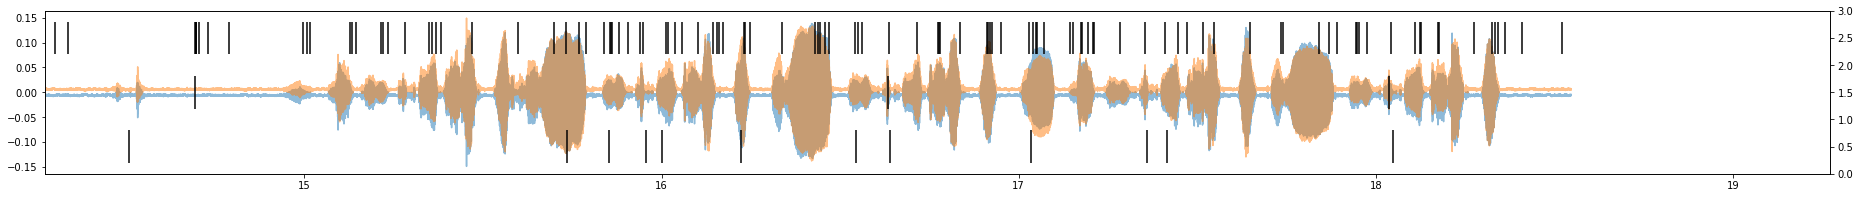

tutor_song_1
54


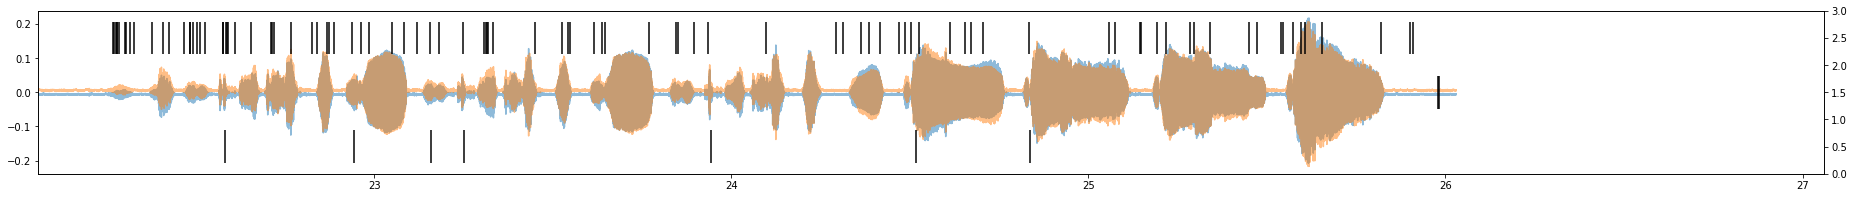

tutor_song_2
55


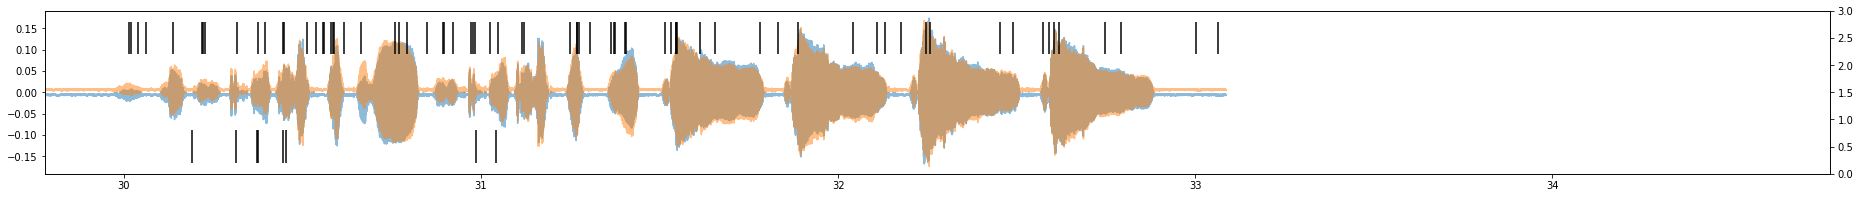

tutor_song_3
56


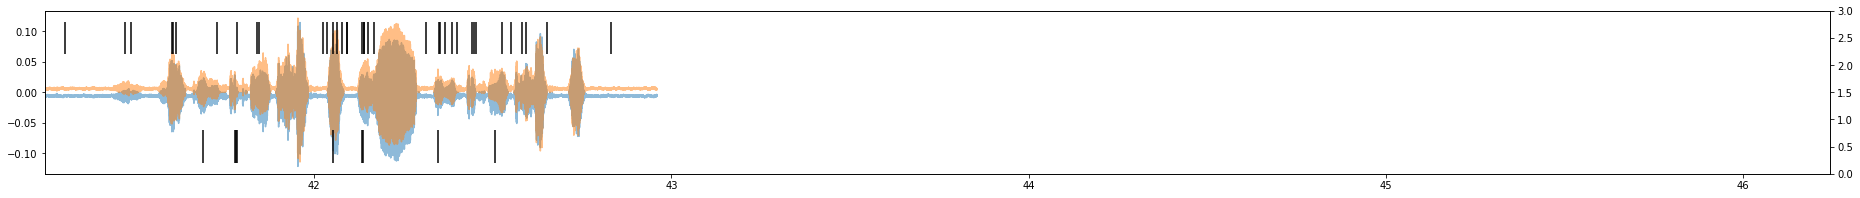

tutor_song_4
57


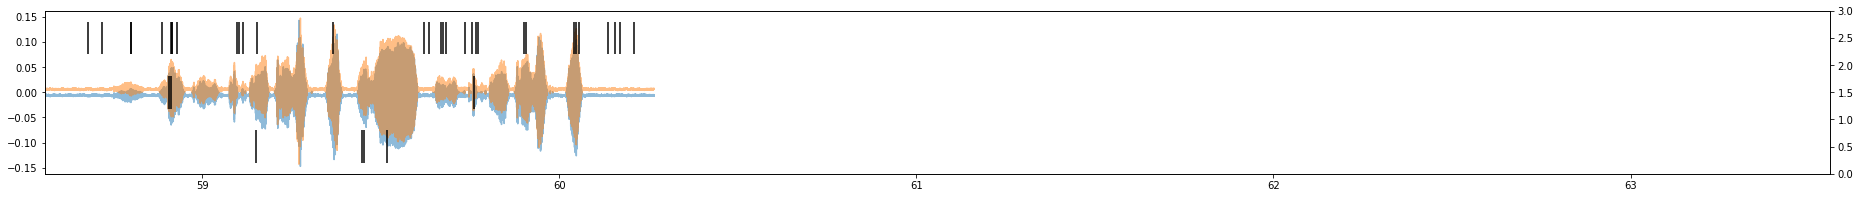

tutor_song_5
58


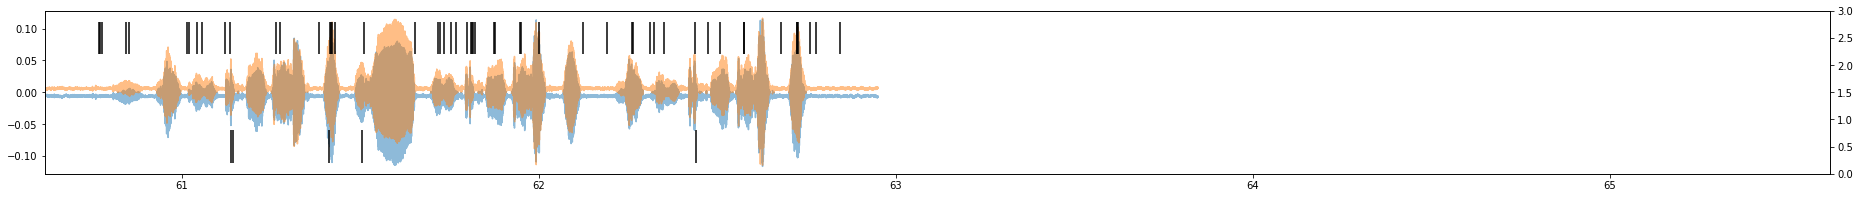

tutor_song_6
59


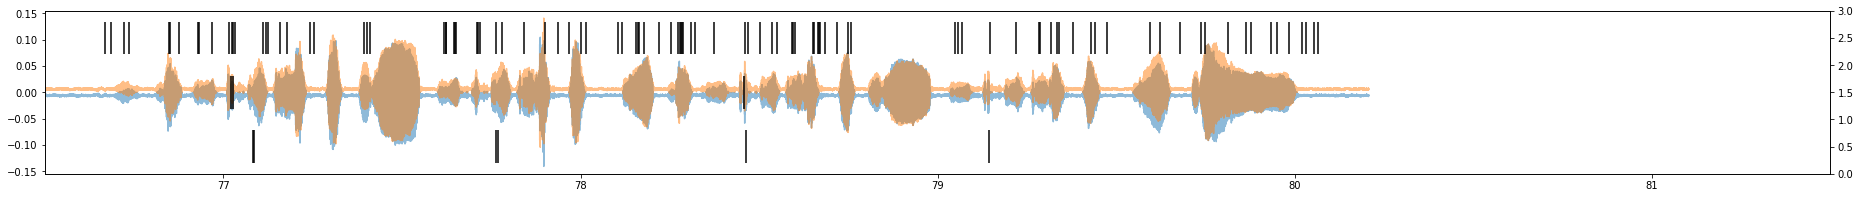

tutor_song_7
60


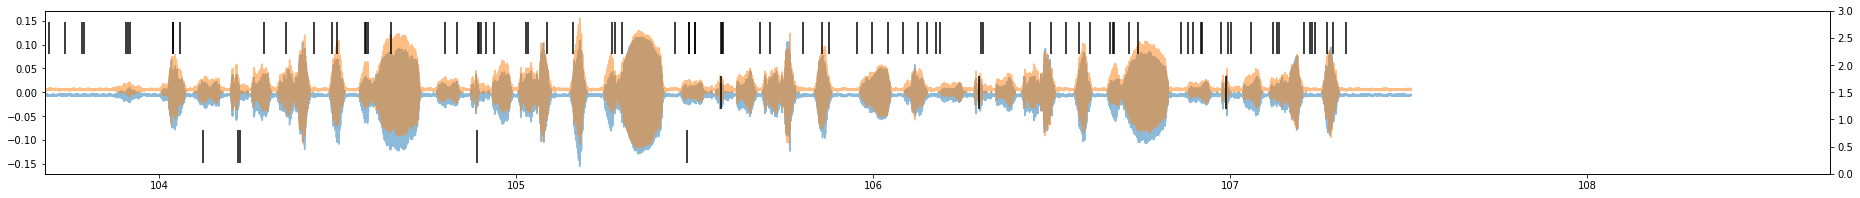

tutor_song_8
61


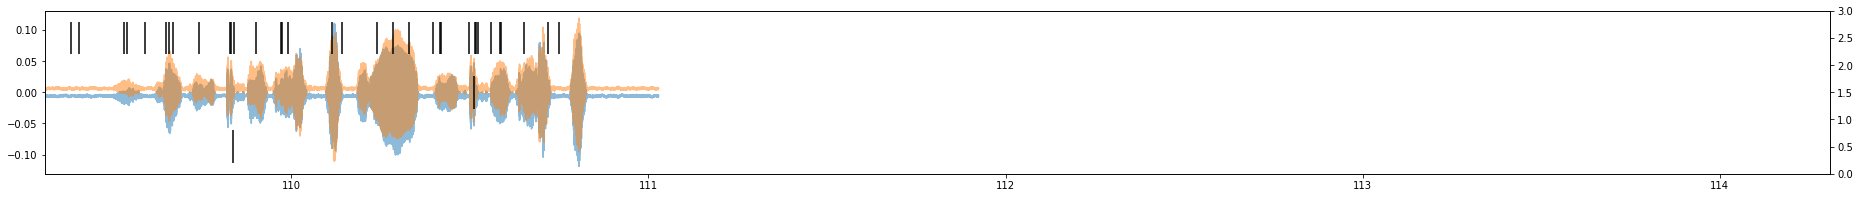

tutor_song_9
62


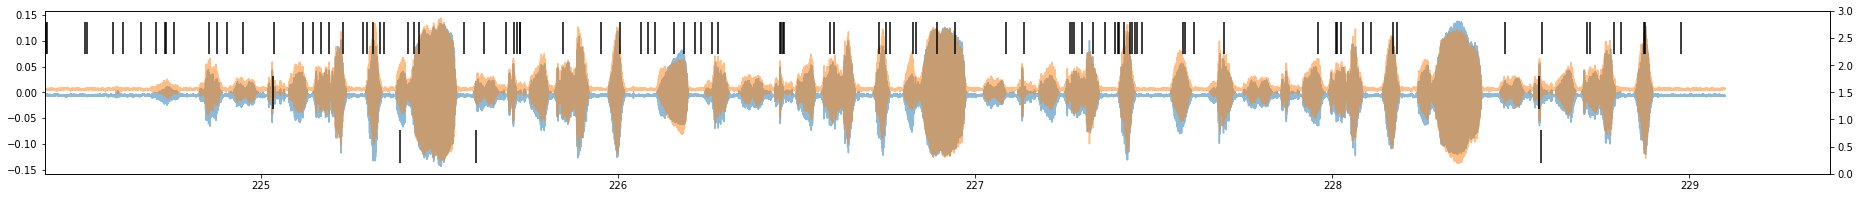

tutor_song_10
63


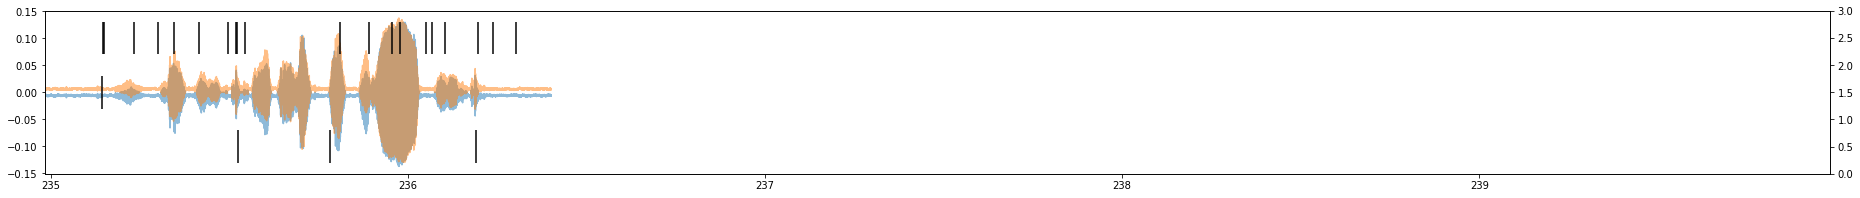

tutor_song_11
64


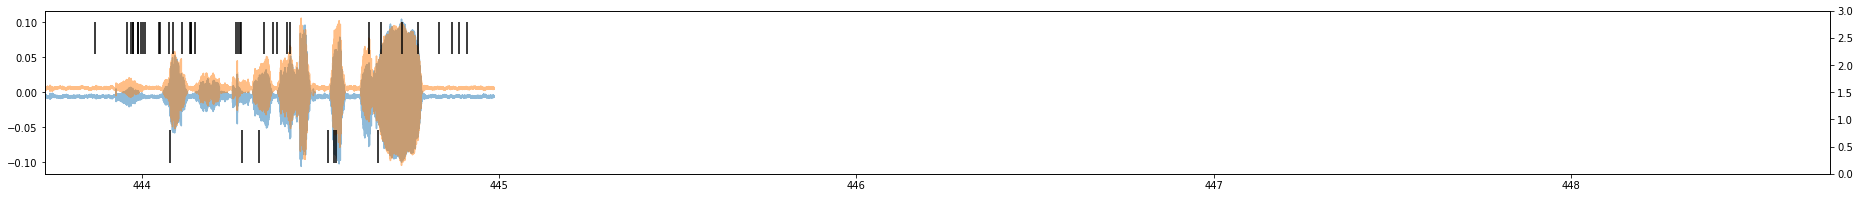

tutor_song_12
65


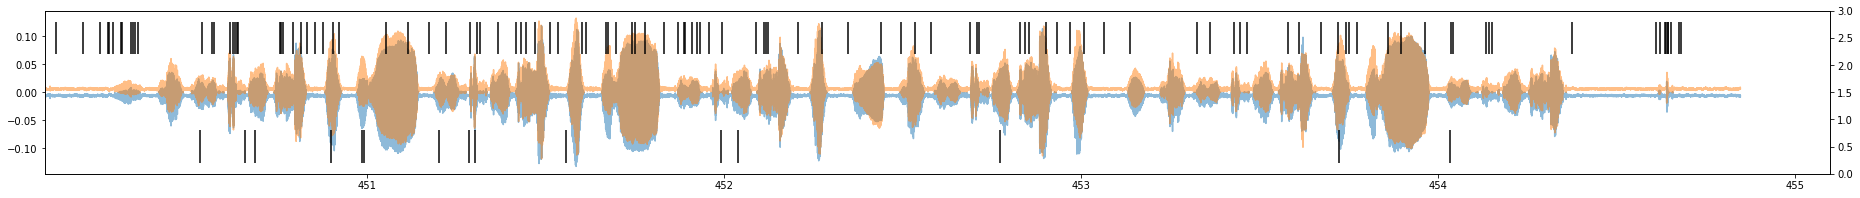

tutor_song_13
66


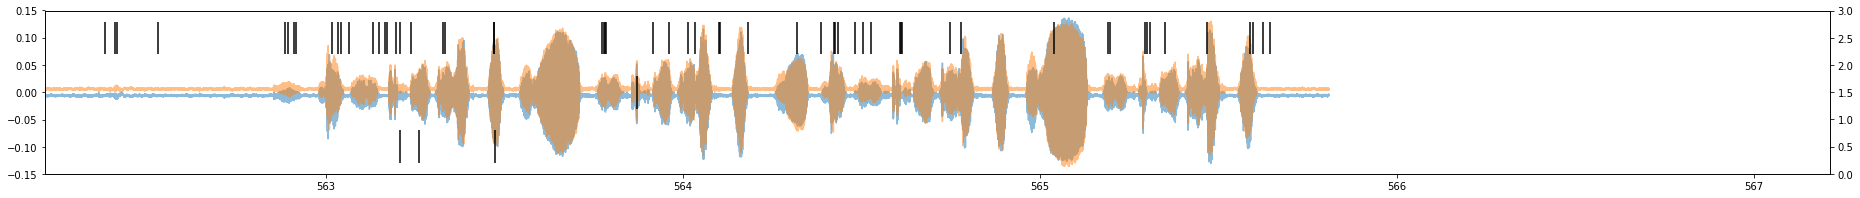

tutor_song_14
67


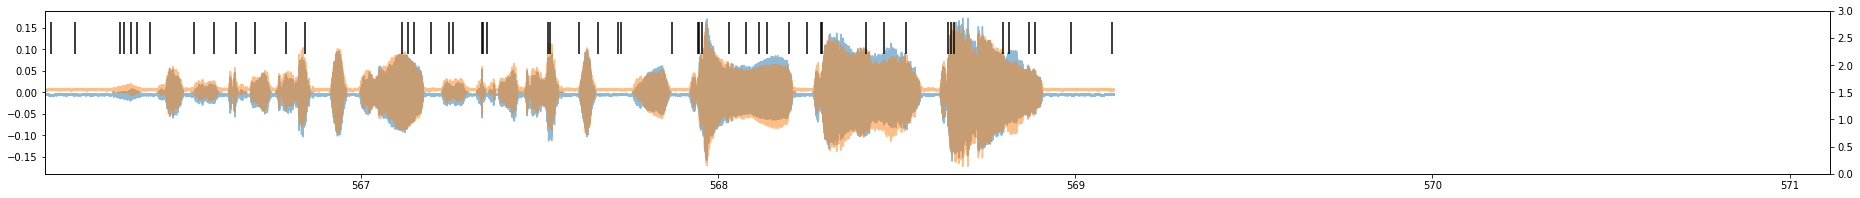

tutor_song_15
68


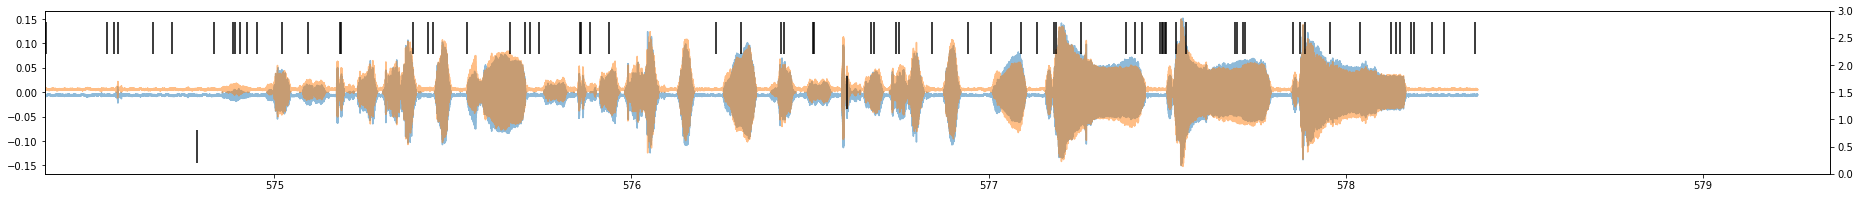

tutor_song_16
69


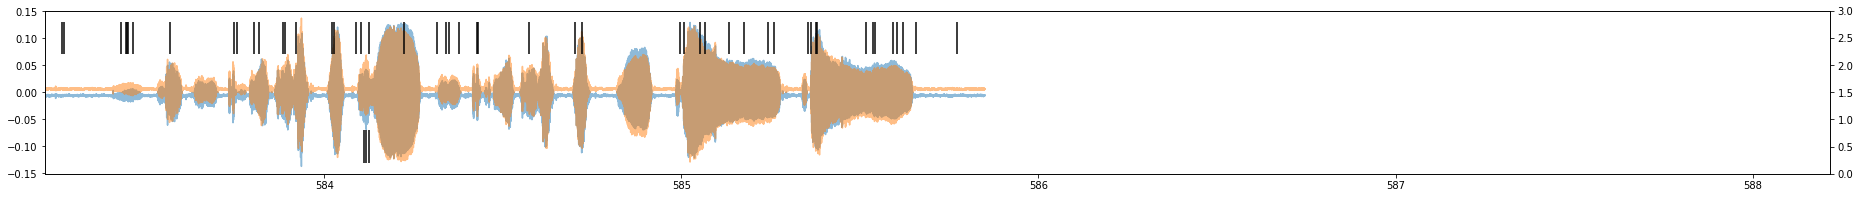

tutor_song_17
70


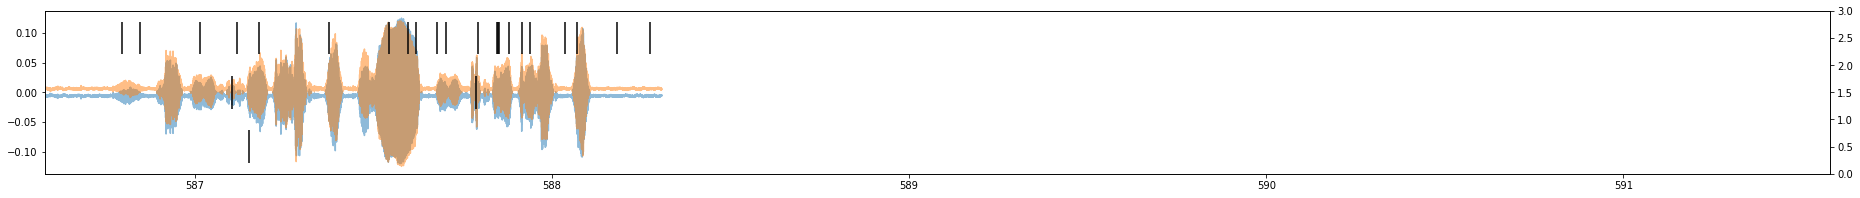

tutor_song_18
71


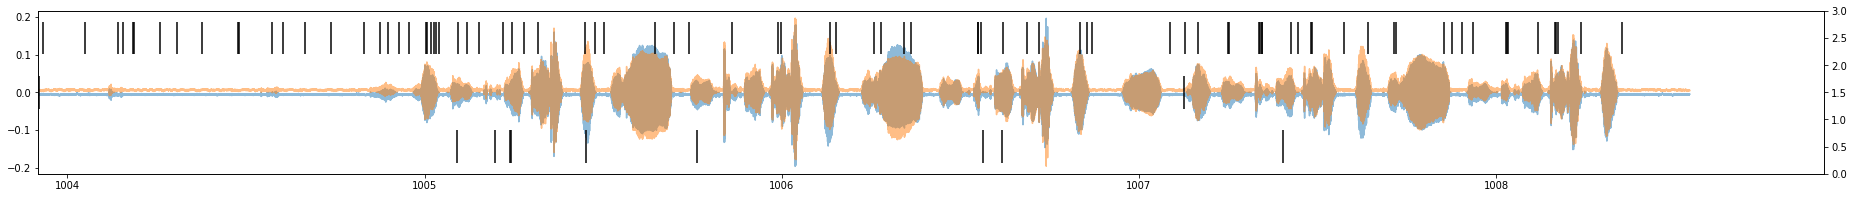

tutor_song_19
72


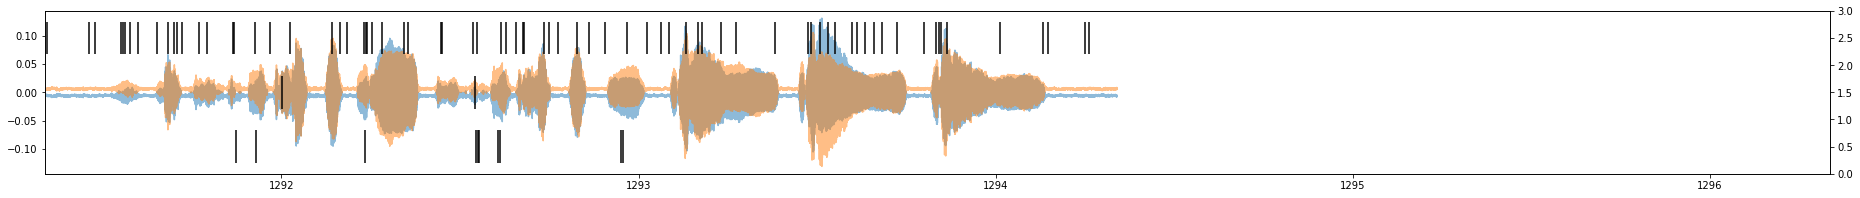

tutor_song_20
73


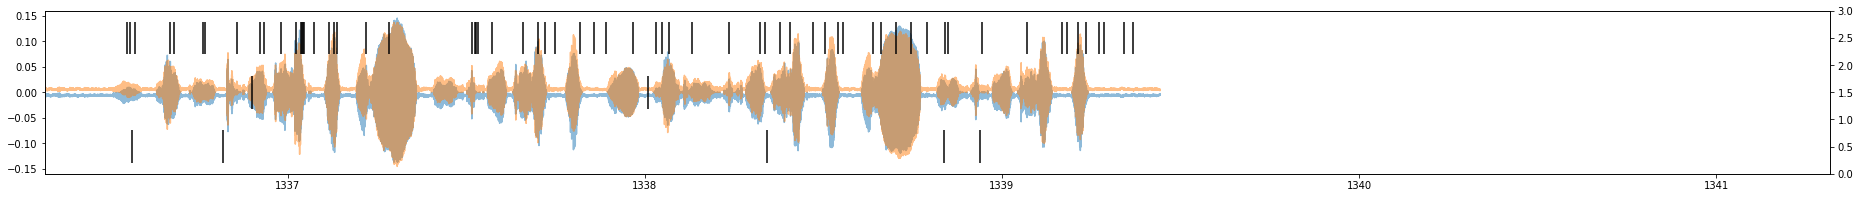

tutor_song_21
74


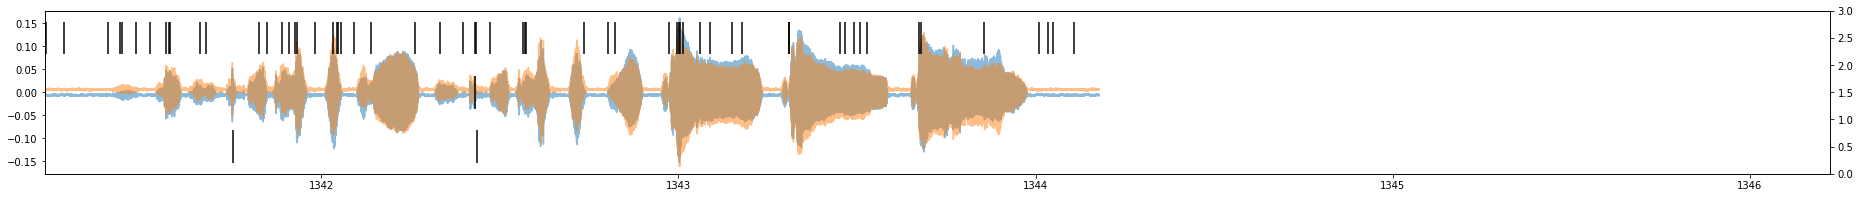

tutor_song_22
75


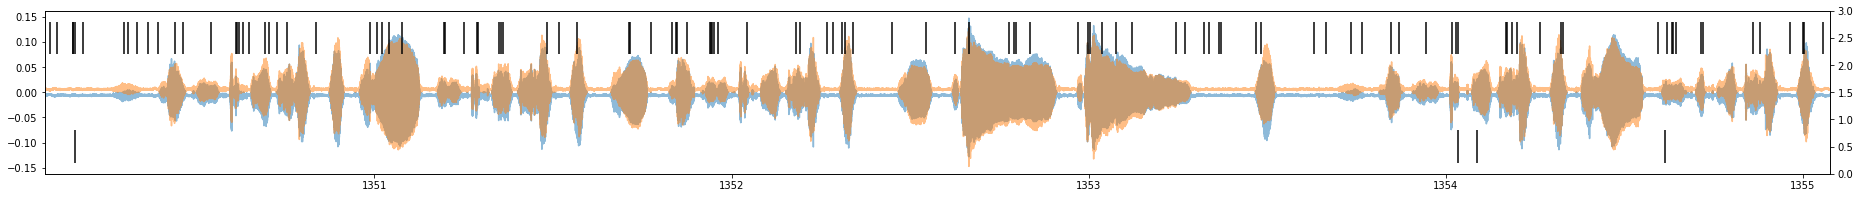

tutor_song_23
76


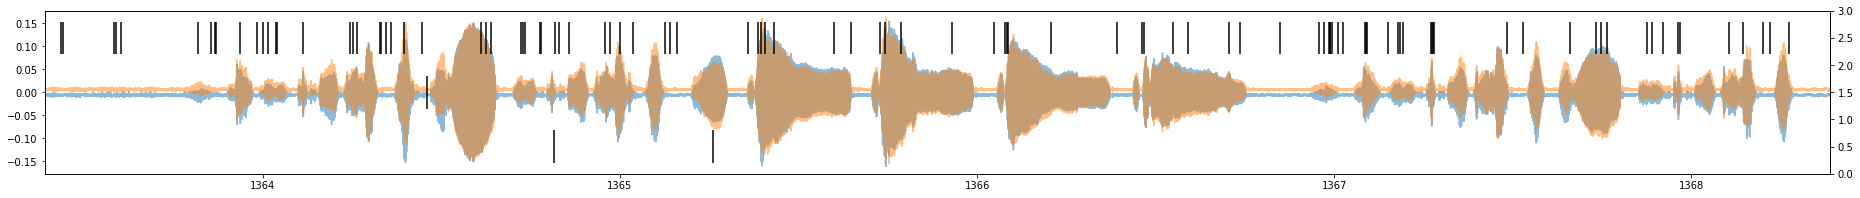

tutor_song_24
77


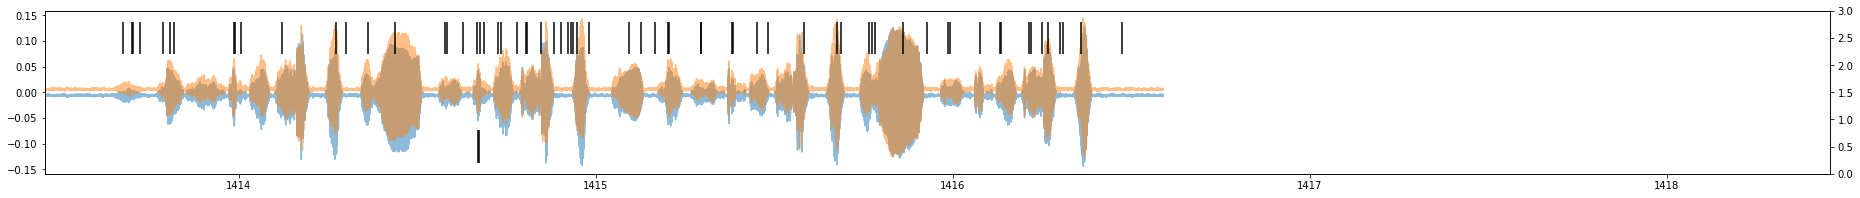

tutor_song_25
78


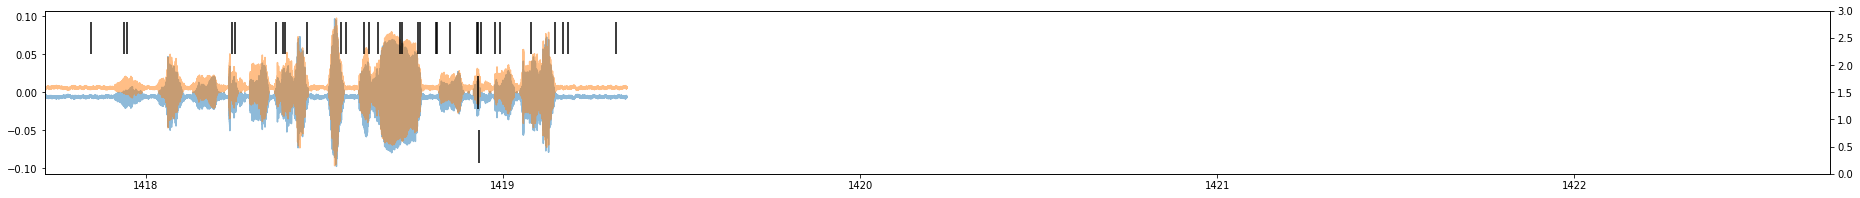

tutor_song_26
79


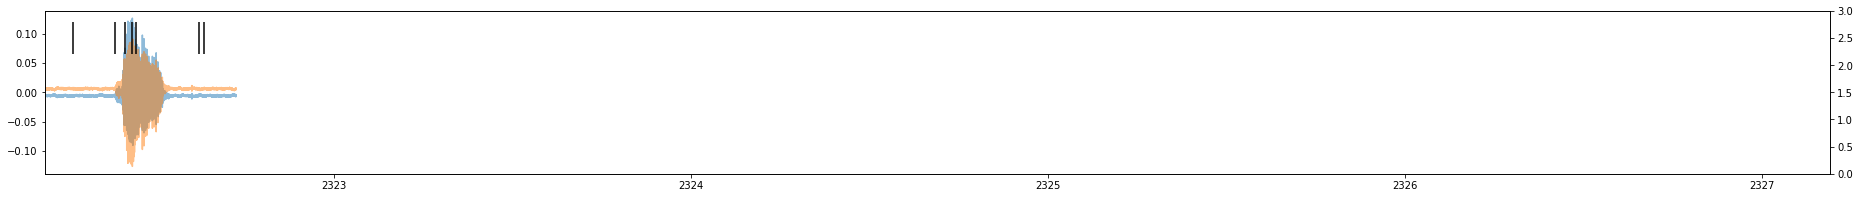

tutor_song_27
80


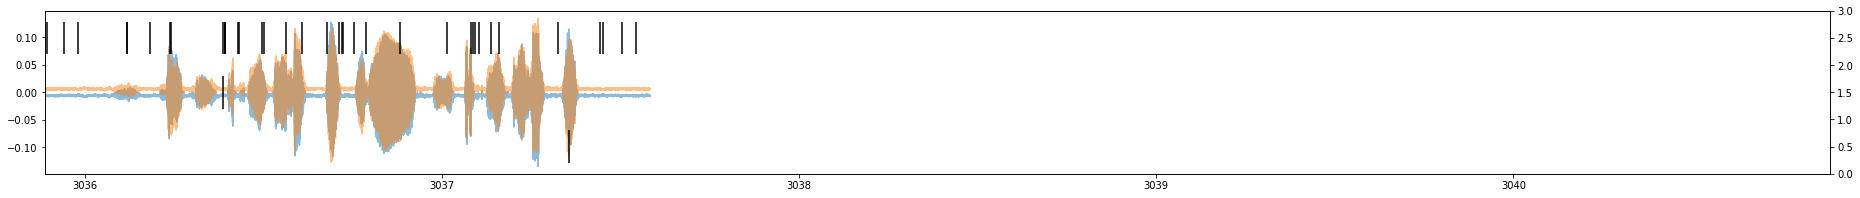

tutor_song_28
81


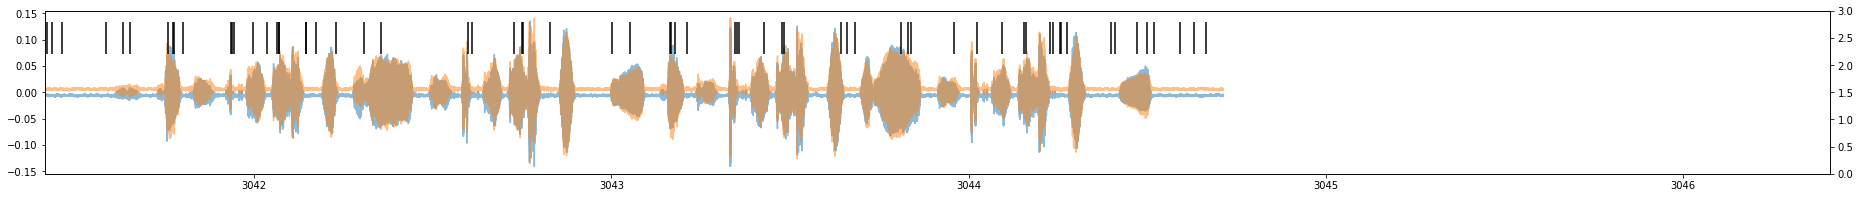

tutor_song_29
82


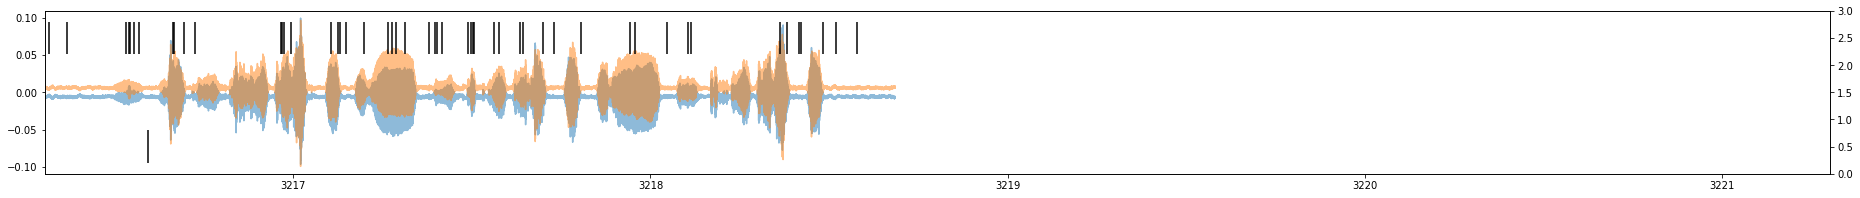

tutor_song_30
83


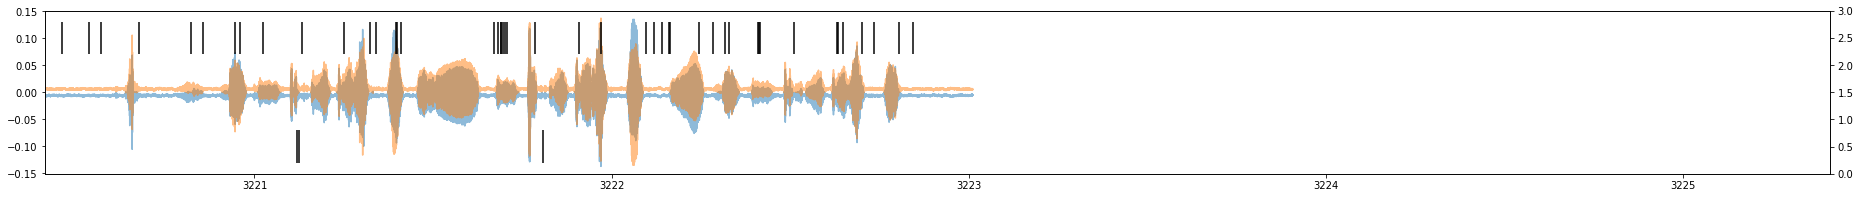

tutor_song_31
84


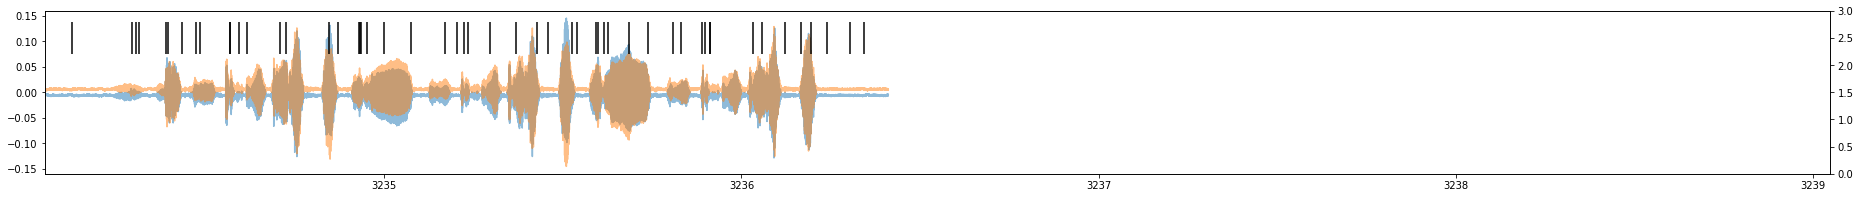

tutor_song_32
85


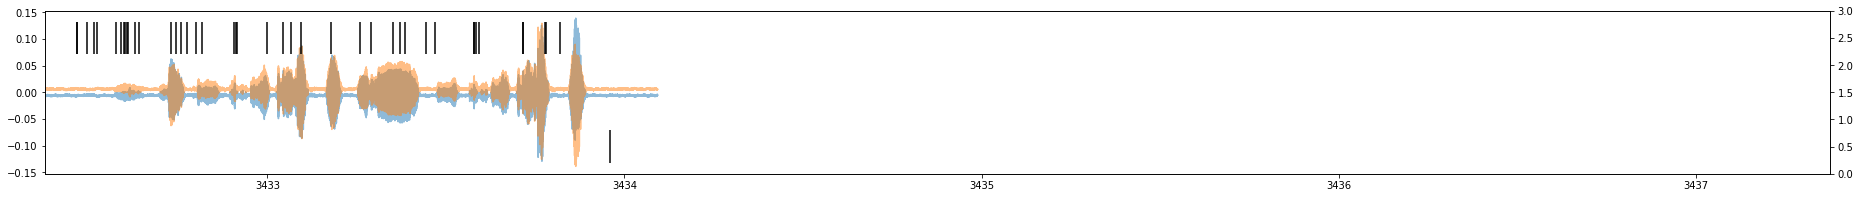

tutor_song_33
86


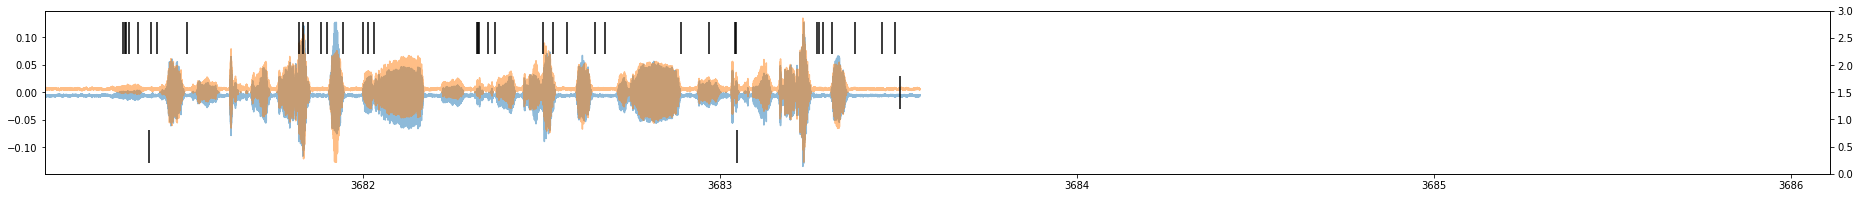

tutor_song_34
87


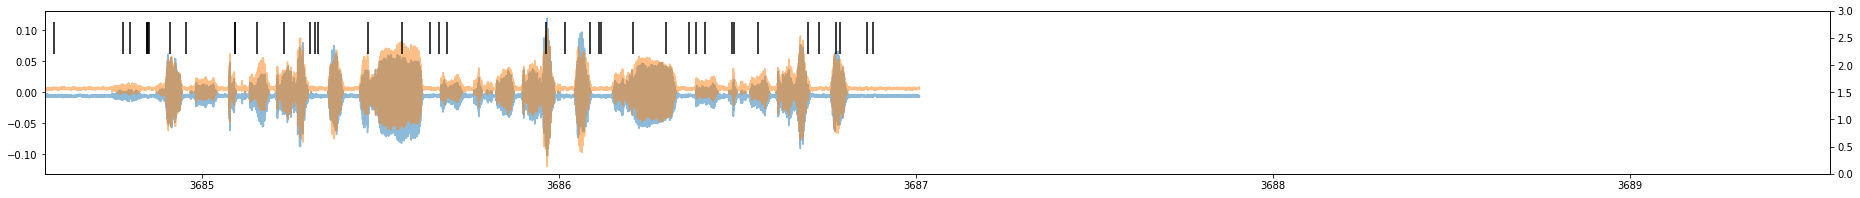

tutor_song_35
88


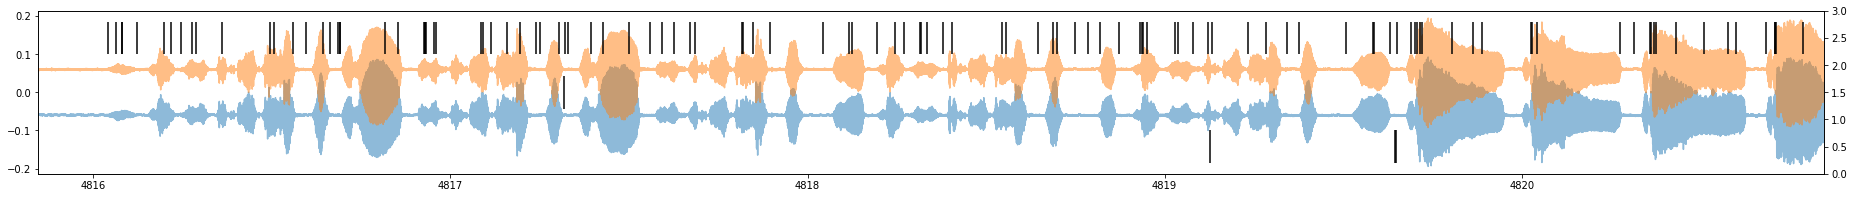

tutor_song_36
89


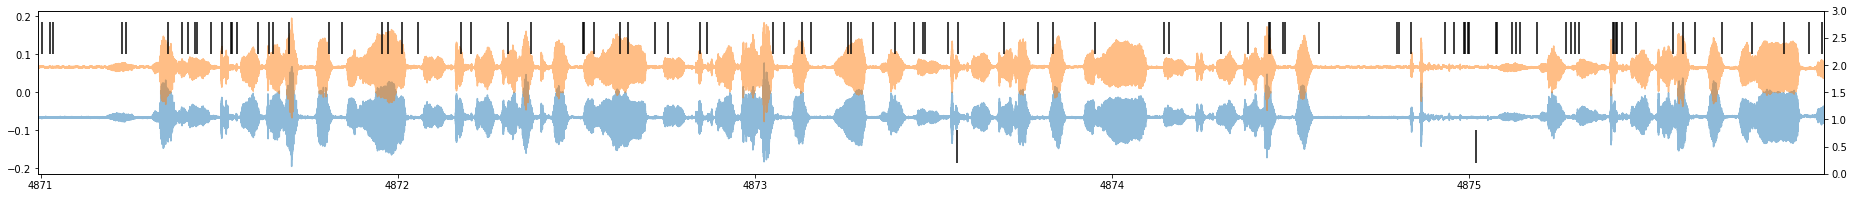

tutor_song_37
90


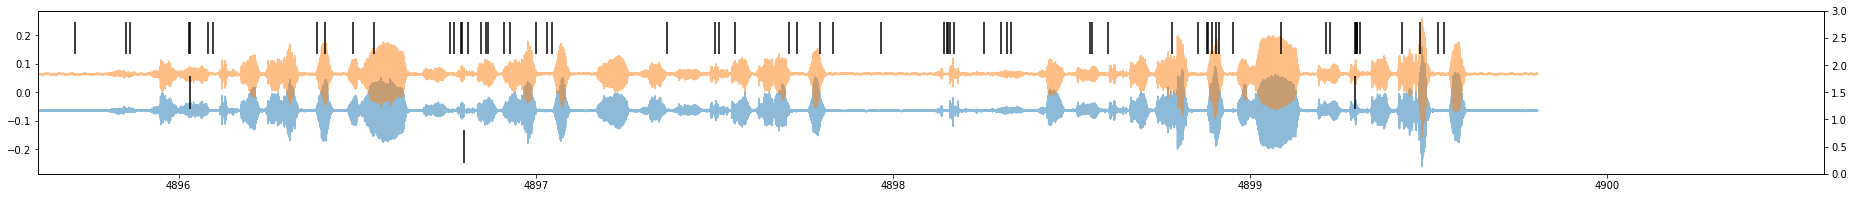

tutor_song_38
91


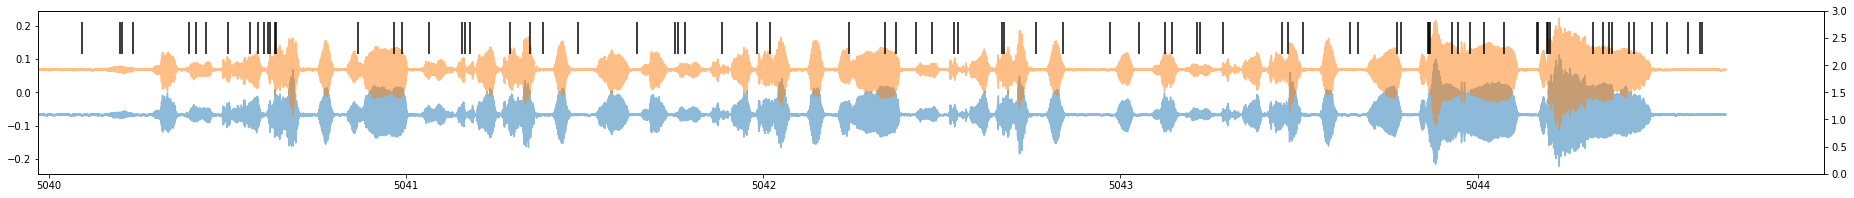

tutor_song_39
92


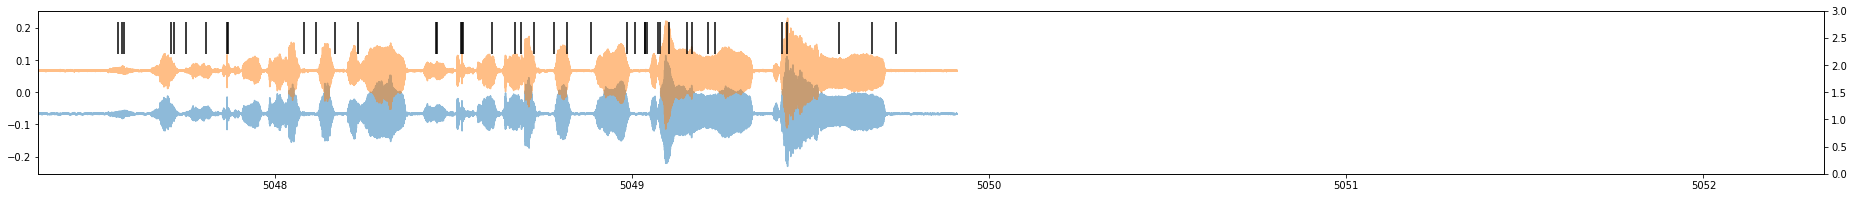

tutor_song_40
93


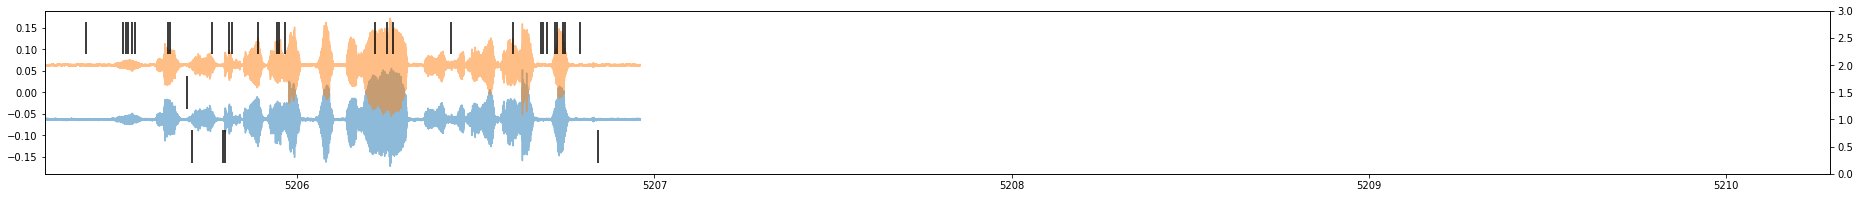

tutor_song_41
94


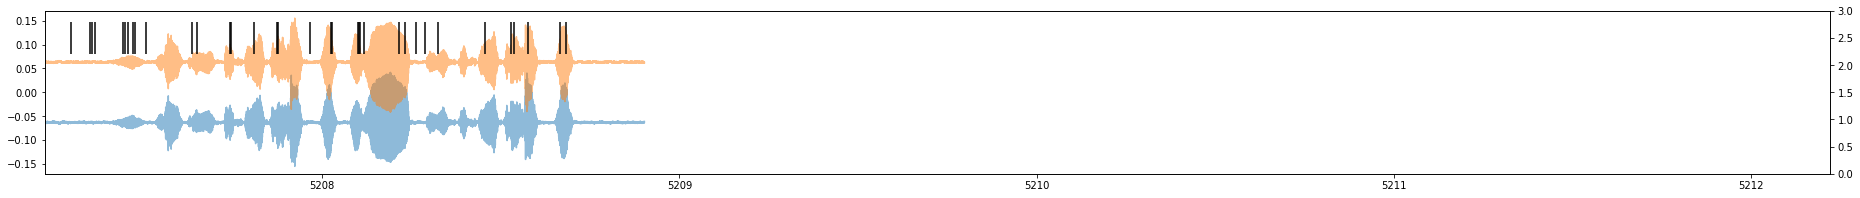

tutor_song_42
95


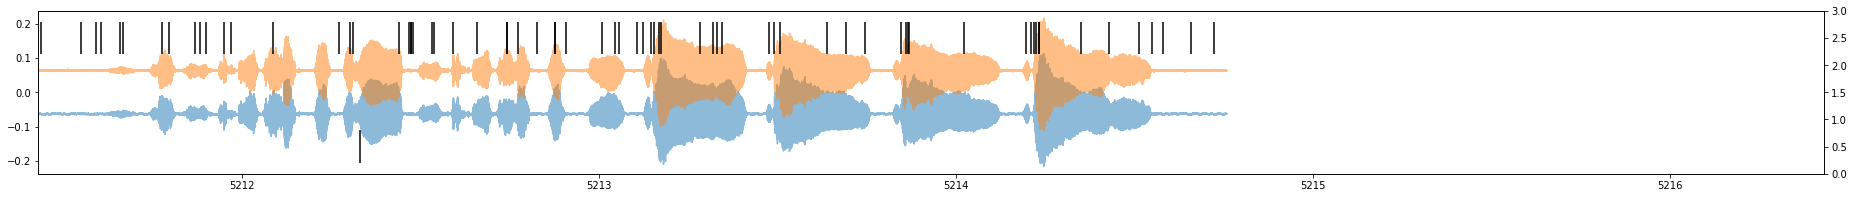

tutor_song_43
96


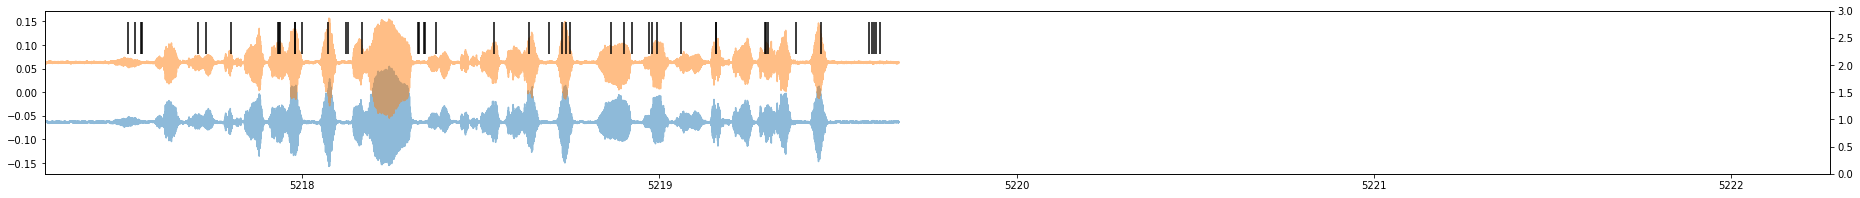

tutor_song_44
97


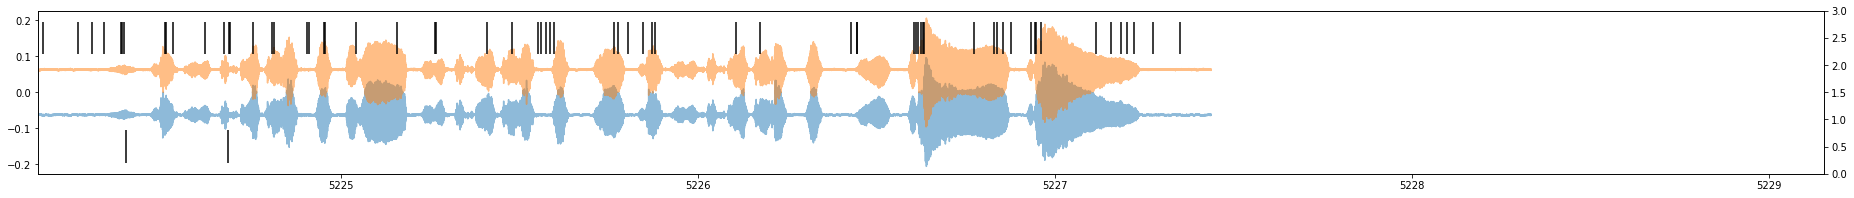

tutor_song_45
98


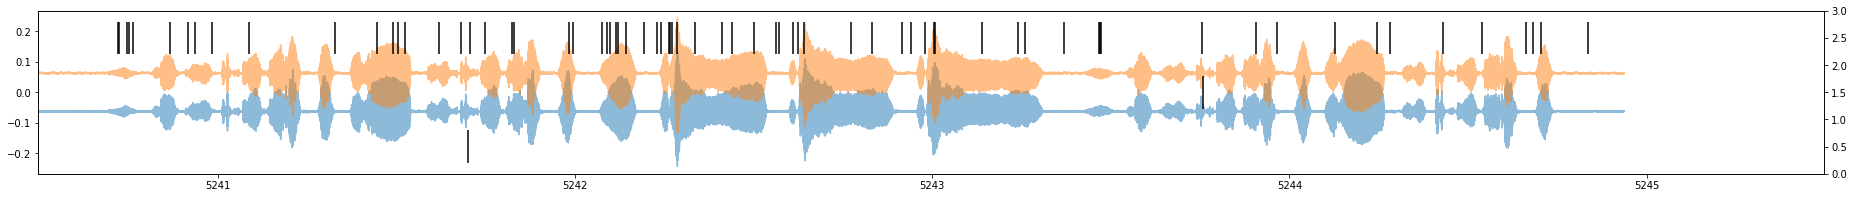

tutor_song_46
99


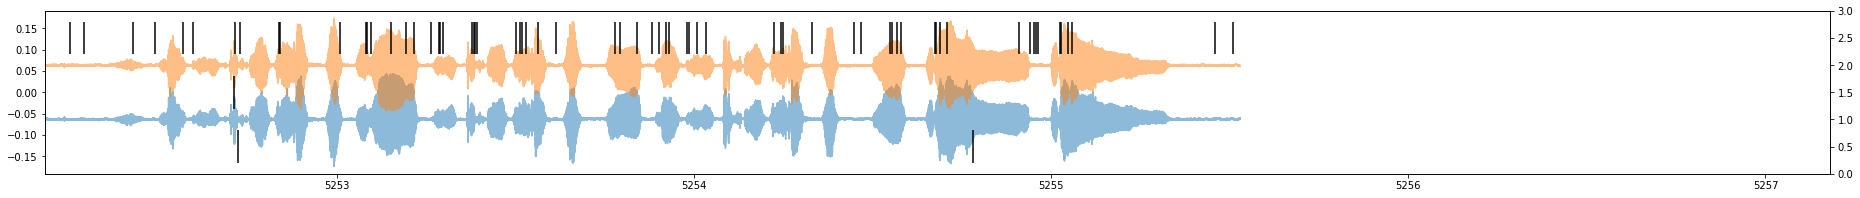

tutor_song_47
100


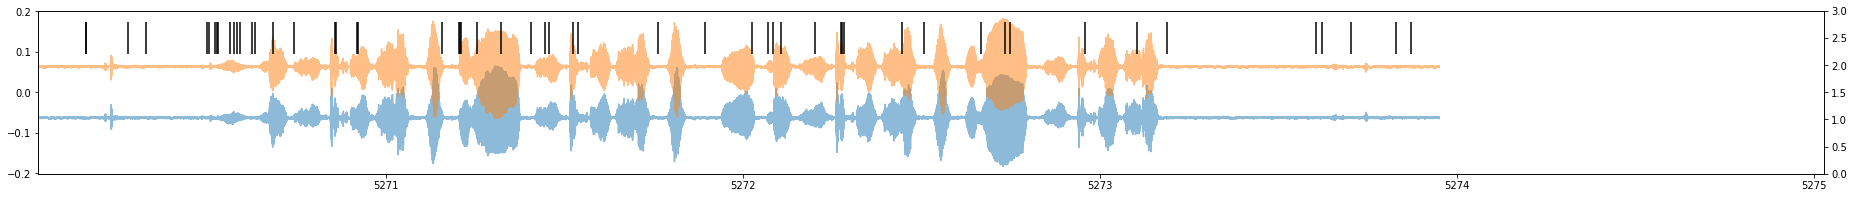

tutor_song_48
101


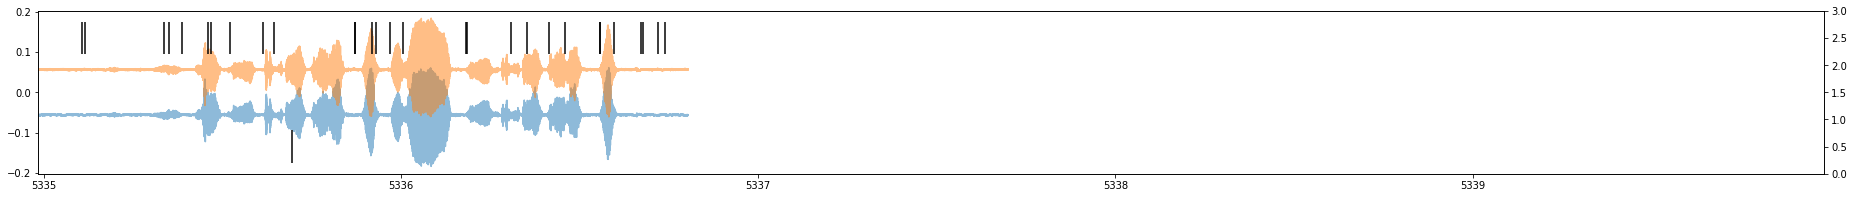

In [297]:
for seg_idx in range(len(new_block.segments)):
    
    seg = new_block.segments[seg_idx]
    
    print seg.name
    print seg_idx
    
    spiketrains = [st for st in seg.spiketrains]

    sound = seg.analogsignals[0].as_array()[:, 0]
    sound1 = seg.analogsignals[0].as_array()[:, 1]
    fig, ax = plt.subplots(figsize=(32, 3))

    plot_spikes_with_timeseries(
        np.linspace(seg.t_start.item(), seg.t_stop.item(), len(sound)),
        spiketrains,
        seg.analogsignals[0].T - np.mean(seg.analogsignals[0].T, axis=0),
        seg.t_start.item(),
        seg.t_start.item() + 5.0,
        ax=ax,
        spike_alpha=1.0,
        y_alpha=[0.5, 0.5]
    )

    plt.show()

In [295]:
analo = seg.analogsignals[0]

In [ ]:
analo.as_array()